# Laboratorio 4 — Segmentación de imágenes con técnicas de agrupación

**Curso:** ISIS2611  
**Integrantes:** David Lucuara-202410218 — Jose Pardo-202411790 *(confirmar)*

> **Propósito:** construir y evaluar un método de segmentación de lesiones para DermAlpes mediante agrupación de píxeles por color y posición.

**Plantilla:** completar el código, las decisiones, las interpretaciones y las conclusiones. Las celdas de código están vacías.

## Tabla de contenido

1. Comprensión del problema
2. Configuración del entorno
3. Carga y exploración de datos
4. Pipeline de preparación y representación
5. Agrupación y selección de K
6. Construcción de la máscara
7. Verificación obligatoria de IAG
8. Ajuste y selección de la configuración
9. Evaluación en prueba
10. Análisis de resultados
11. Conclusiones
12. Guion del video
13. Uso de herramientas de IA generativa
14. Referencias y revisión de entregables
15. Bonos

# 1. Comprensión del problema

## 1.1 Contexto

DermAlpes conecta centros de salud de municipios pequeños con dermatólogos ubicados en ciudades principales. El personal de estos centros captura imágenes de lesiones de piel con un dermatoscopio y las envía para revisión a distancia. La empresa busca delimitar automáticamente la región de la lesión para facilitar que el especialista revise su tamaño y forma y concentre su atención en la zona relevante.

Como primera aproximación, se evaluará un método de segmentación basado en K-medias que agrupe los píxeles según su color y posición. DermAlpes no dispone de imágenes etiquetadas de sus propios pacientes; por ello, se utilizará la selección de imágenes públicas y máscaras de referencia indicada en el enunciado. Estas máscaras permiten evaluar la segmentación, pero no intervienen en el agrupamiento de los píxeles.

**Alcance:** construir y evaluar un prototipo de apoyo a la delimitación de lesiones. La herramienta no diagnostica enfermedades ni sustituye la valoración del dermatólogo. Su desempeño en esta selección de imágenes no demuestra que funcione en otras poblaciones o condiciones de adquisición.

## 1.2 Objetivos y unidad de análisis

### Objetivo general

Construir y evaluar un método de segmentación de lesiones mediante agrupación de píxeles por color y posición, seleccionando su configuración con imágenes de ajuste y estimando su desempeño en imágenes de prueba reservadas.

### Objetivos específicos

1. Implementar un pipeline de Scikit-learn que represente cada píxel mediante `[β·R, β·G, β·B, λ·x, λ·y]`, con colores y coordenadas normalizados a [0,1] antes de aplicar los pesos. Preparar máscaras binarias compatibles con las dimensiones de las imágenes.
2. Explorar diez combinaciones de β y λ con distintas razones de peso, incluyendo solo color y solo posición. Para cada imagen y combinación, evaluar K entre 2 y 8 y seleccionarlo mediante silueta sobre una muestra reproducible de píxeles, documentando su tamaño y semilla.
3. Diseñar y justificar un criterio automático que transforme los grupos en una máscara de lesión, sin seleccionar manualmente los clústeres por imagen ni utilizar la referencia para identificarlos.
4. Seleccionar β, λ y el criterio de construcción de la máscara mediante Dice promedio en las 15 imágenes de ajuste, considerando V-measure como información complementaria y revisando los casos de fallo.
5. Evaluar la configuración seleccionada, sin modificaciones, en las cinco imágenes de prueba; comparar ajuste y prueba y analizar limitaciones, consecuencias de los errores y posibles problemas de generalización.

### Unidad de análisis y salida esperada

| Elemento | Definición en este laboratorio |
|---|---|
| Instancia para K-medias | Un píxel de una imagen, representado por cinco características de color y posición ponderadas. |
| Unidad de segmentación y evaluación | Una imagen completa, sobre la que se ajusta K-medias y se calculan las métricas. |
| Salida del agrupamiento | Un identificador de clúster por píxel; ese identificador no significa por sí mismo «lesión». |
| Salida final | Una máscara binaria con 1 = lesión y 0 = piel o fondo, obtenida mediante un criterio automático sobre los grupos. |
| Referencia | Máscara elaborada por especialistas, utilizada para comparar resultados según la separación entre ajuste y prueba. |
| Tipo de problema | Segmentación mediante agrupación no supervisada; el ajuste de la configuración sí se apoya en referencias de las imágenes de ajuste. |

## 1.3 Protocolo de ajuste y evaluación

Se utilizarán exclusivamente los **20 identificadores fijados por el enunciado**, con su separación predefinida de **15 imágenes de ajuste y 5 de prueba**. Esta división corresponde al laboratorio y no se reemplazará por una partición aleatoria de las imágenes descargadas. Las listas se documentan en la sección 3.

1. **Preparación y exploración de ajuste.** Revisar los 15 pares de ajuste, definir el procesamiento de imágenes y preparar las referencias. Si se reduce la resolución, conservar la correspondencia espacial y redimensionar las máscaras con vecino más cercano para mantener sus etiquetas binarias.
2. **Selección de K sin referencias.** Para cada imagen de ajuste y cada combinación de pesos, agrupar los píxeles y seleccionar K por silueta sobre una muestra reproducible. Las referencias no se utilizarán como entrada de K-medias ni para elegir K.
3. **Construcción y ajuste de la máscara.** Aplicar el criterio automático a los grupos. Las referencias de ajuste se utilizarán para evaluar y comparar configuraciones globales, no para escoger a posteriori el clúster de lesión de cada imagen.
4. **Verificación de IAG.** Antes de seleccionar la configuración final, realizar la consulta obligatoria sin imágenes ni nombre del dataset, conservar el historial y contrastar su recomendación únicamente con imágenes de ajuste.
5. **Selección y fijación del método.** Elegir β, λ y el criterio mediante Dice promedio de ajuste, documentando V-measure y fallos. Fijar también las decisiones de procesamiento, las semillas, el muestreo, la regla de selección de K y cualquier posprocesamiento antes de evaluar prueba.
6. **Evaluación final independiente.** Consultar las cinco imágenes de prueba y sus referencias solo al final. Aplicar el método sin modificarlo. K se seleccionará para cada nueva imagen mediante la misma regla de silueta ya establecida; no tiene que ser el mismo para todas las imágenes y no se elegirá utilizando las máscaras de prueba.

### Métricas y evidencia que se presentarán

| Medida | Qué evalúa | Uso en el protocolo |
|---|---|---|
| Silueta | Separación y cohesión de los grupos en el espacio de características. | Seleccionar K por imagen sin usar referencias. |
| Dice | Superposición entre la máscara estimada y la referencia, considerando lesión como clase positiva; equivale al F1 a nivel de píxel. | Criterio principal: promedio de los Dice de las 15 imágenes de ajuste, con igual peso por imagen. Reportar también cada imagen y el promedio en prueba. |
| V-measure | Correspondencia entre los identificadores de clúster y las etiquetas binarias de referencia. | Información complementaria; se calcula con los grupos originales, no con la máscara estimada. |
| Precisión y recall | Respectivamente, proporción de píxeles predichos como lesión que son correctos y proporción de lesión de referencia que se recupera. | Caracterizar falsos positivos y falsos negativos en prueba, con lesión como clase positiva. |

En prueba se presentará una tabla con **K, silueta, Dice, V-measure, precisión y recall para cada una de las cinco imágenes**, acompañada de la imagen original, la máscara estimada y la referencia. En ajuste se visualizarán originales y grupos de las dos configuraciones con mayor Dice promedio y de las configuraciones de solo color y solo posición.

El análisis comparará el Dice promedio de ambos conjuntos y examinará ejemplos concretos de mejora, deterioro y fallo. También distinguirá la calidad geométrica del agrupamiento de la calidad de la segmentación: una silueta o un V-measure altos no garantizan un Dice alto. No se modificarán pesos, criterios ni otras decisiones después de observar prueba, pues hacerlo convertiría ese conjunto en parte del ajuste y comprometería la independencia de la evaluación.


# 2. Configuración del entorno

Se utiliza Python en el entorno `.venv` compartido por los laboratorios. En VS Code se debe seleccionar ese entorno como kernel del notebook.

- **NumPy y pandas:** representación de píxeles y organización de resultados.
- **Pillow:** lectura de imágenes y máscaras y, si se decide reducir la resolución, redimensionamiento con interpolación apropiada.
- **Matplotlib y Seaborn:** visualización de imágenes, agrupaciones y resultados.
- **Scikit-learn:** pipeline, transformación de características, K-medias y métricas de evaluación.

Se fija una semilla para reproducir el muestreo y la inicialización de K-medias. La semilla deberá pasarse explícitamente como `random_state` en las operaciones correspondientes. También se registran las versiones instaladas, porque una semilla por sí sola no garantiza resultados idénticos entre versiones diferentes.

El rango de K = 2,…,8 lo establece el enunciado. La resolución de trabajo, el tamaño de la muestra de silueta, las diez combinaciones de pesos y los parámetros adicionales de K-medias se definirán y justificarán en sus respectivas secciones, utilizando únicamente ajuste. No se suprimen las advertencias de las librerías para poder detectar problemas de ejecución.

In [5]:
from pathlib import Path
from time import perf_counter
from importlib.metadata import version
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    f1_score,
    v_measure_score,
    precision_score,
    recall_score,
)

RANDOM_STATE = 42
K_CANDIDATOS = tuple(range(2, 9))


pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid")

print("Intérprete:", sys.executable)
print("Python:", sys.version.split()[0])
for paquete in ["numpy", "pandas", "Pillow", "matplotlib", "seaborn", "scikit-learn", "ipykernel"]:
    print(f"{paquete}: {version(paquete)}")
print("Semilla:", RANDOM_STATE)
print("K candidatos:", K_CANDIDATOS)


Intérprete: /home/jose/uni/ml/labs/.venv/bin/python
Python: 3.12.3
numpy: 2.5.4
pandas: 3.1.0
Pillow: 13.0.0
matplotlib: 3.11.2
seaborn: 0.13.2
scikit-learn: 1.9.1
ipykernel: 7.4.0
Semilla: 42
K candidatos: (2, 3, 4, 5, 6, 7, 8)


# 3. Carga y exploración de datos

## 3.1 Fuente y selección de imágenes
Los archivos ya están descargados en `datos/imagenes/` y `datos/mascaras/`, con sus subcarpetas originales. Fuente: [ISIC 2016 — tarea 1](https://challenge.isic-archive.com/landing/2016/37/).

El enunciado fija esta selección; las demás imágenes descargadas no forman parte del protocolo:

| Ajuste | Ajuste | Ajuste | Prueba |
|---|---|---|---|
| ISIC_0000085 | ISIC_0000114 | ISIC_0000150 | ISIC_0000087 |
| ISIC_0000086 | ISIC_0000116 | ISIC_0000153 | ISIC_0000105 |
| ISIC_0000089 | ISIC_0000122 | ISIC_0000156 | ISIC_0000110 |
| ISIC_0000094 | ISIC_0000133 | ISIC_0000157 | ISIC_0000123 |
| ISIC_0000108 | ISIC_0000137 | ISIC_0000112 | ISIC_0000128 |

Se cargan exclusivamente los 15 pares de ajuste, conservando su resolución original. Los cinco identificadores de prueba se registran para documentar la separación, pero sus imágenes y máscaras no se abren en esta sección. Las subcarpetas originales de los ZIP se recorren por nombre exacto; se exige un único archivo por identificador para evitar emparejamientos ambiguos.

In [6]:
# Localizar los datos tanto al ejecutar desde labs como desde EntregaLab4.
carpeta_actual = Path.cwd()
if (carpeta_actual / "datos" / "imagenes").is_dir():
    CARPETA_LAB4 = carpeta_actual
elif (carpeta_actual / "EntregaLab4" / "datos" / "imagenes").is_dir():
    CARPETA_LAB4 = carpeta_actual / "EntregaLab4"
else:
    raise FileNotFoundError("No se encontró datos/imagenes. Ejecutar desde labs o EntregaLab4.")

CARPETA_IMAGENES = CARPETA_LAB4 / "datos" / "imagenes"
CARPETA_MASCARAS = CARPETA_LAB4 / "datos" / "mascaras"

IDS_AJUSTE = [
    "ISIC_0000085", "ISIC_0000086", "ISIC_0000089", "ISIC_0000094", "ISIC_0000108",
    "ISIC_0000114", "ISIC_0000116", "ISIC_0000122", "ISIC_0000133", "ISIC_0000137",
    "ISIC_0000150", "ISIC_0000153", "ISIC_0000156", "ISIC_0000157", "ISIC_0000112",
]
IDS_PRUEBA = ["ISIC_0000087", "ISIC_0000105", "ISIC_0000110", "ISIC_0000123", "ISIC_0000128"]
assert len(set(IDS_AJUSTE)) == 15 and len(set(IDS_PRUEBA)) == 5
assert set(IDS_AJUSTE).isdisjoint(IDS_PRUEBA)


def buscar_archivo(carpeta, nombre):
    coincidencias = sorted(carpeta.rglob(nombre))
    if len(coincidencias) != 1:
        raise FileNotFoundError(f"Se esperaba un archivo {nombre}; encontrados: {len(coincidencias)}")
    return coincidencias[0]


ajuste = {}
for identificador in IDS_AJUSTE:
    ruta_imagen = buscar_archivo(CARPETA_IMAGENES, identificador + ".jpg")
    ruta_mascara = buscar_archivo(CARPETA_MASCARAS, identificador + "_Segmentation.png")
    with Image.open(ruta_imagen) as archivo:
        if archivo.mode != "RGB":
            raise ValueError(f"{identificador}: modo de imagen inesperado {archivo.mode}")
        imagen = np.array(archivo)
    with Image.open(ruta_mascara) as archivo:
        mascara = np.array(archivo)
    if mascara.ndim != 2 or imagen.shape[:2] != mascara.shape:
        raise ValueError(f"{identificador}: dimensiones incompatibles entre imagen y máscara")
    valores = np.unique(mascara)
    if not np.isin(valores, [0, 255]).all():
        raise ValueError(f"{identificador}: valores de máscara inesperados {valores}")
    ajuste[identificador] = {"imagen": imagen, "mascara_original": mascara}

print("Carpeta de datos:", CARPETA_LAB4 / "datos")
print(f"Pares de ajuste cargados: {len(ajuste)}/15")
print("Imágenes de prueba abiertas: 0; permanecen reservadas.")


Carpeta de datos: /home/jose/uni/ml/labs/EntregaLab4/datos
Pares de ajuste cargados: 15/15
Imágenes de prueba abiertas: 0; permanecen reservadas.


## 3.2 Contenido y calidad de los datos

Se comprueba la completitud de los 15 pares, la correspondencia de sus dimensiones y que las máscaras contengan exclusivamente valores 0 y 255. Se reportan resolución, tipo de dato y proporción de píxeles de lesión por imagen. Esta proporción describe las referencias de ajuste; no se utiliza para identificar los grupos de lesión.

La galería permite revisar contraste, iluminación, vello y otros elementos que podrían afectar un método basado en color y posición. Las imágenes y máscaras se muestran con sus coordenadas correspondientes, sin redimensionar los arreglos almacenados. La conversión de máscaras a 0/1 y cualquier cambio de resolución se realizarán en la sección 4.

,ancho,alto,pixeles,tipo_imagen,tipo_mascara,valores_mascara,lesion_%,dimensiones_coinciden
imagen,,,,,,,,
ISIC_0000085,2048,1536,3145728,uint8,uint8,"[0, 255]",12.65,True
ISIC_0000086,2592,1944,5038848,uint8,uint8,"[0, 255]",23.36,True
ISIC_0000089,2048,1536,3145728,uint8,uint8,"[0, 255]",12.14,True
ISIC_0000094,2048,1536,3145728,uint8,uint8,"[0, 255]",5.94,True
ISIC_0000108,2048,1536,3145728,uint8,uint8,"[0, 255]",18.49,True
ISIC_0000114,2048,1536,3145728,uint8,uint8,"[0, 255]",3.15,True
ISIC_0000116,2048,1536,3145728,uint8,uint8,"[0, 255]",36.08,True
ISIC_0000122,2048,1536,3145728,uint8,uint8,"[0, 255]",39.01,True
ISIC_0000133,2048,1536,3145728,uint8,uint8,"[0, 255]",14.16,True


Total de píxeles de ajuste: 48,432,159
Referencias vacías: 0
Referencias que ocupan toda la imagen: 0


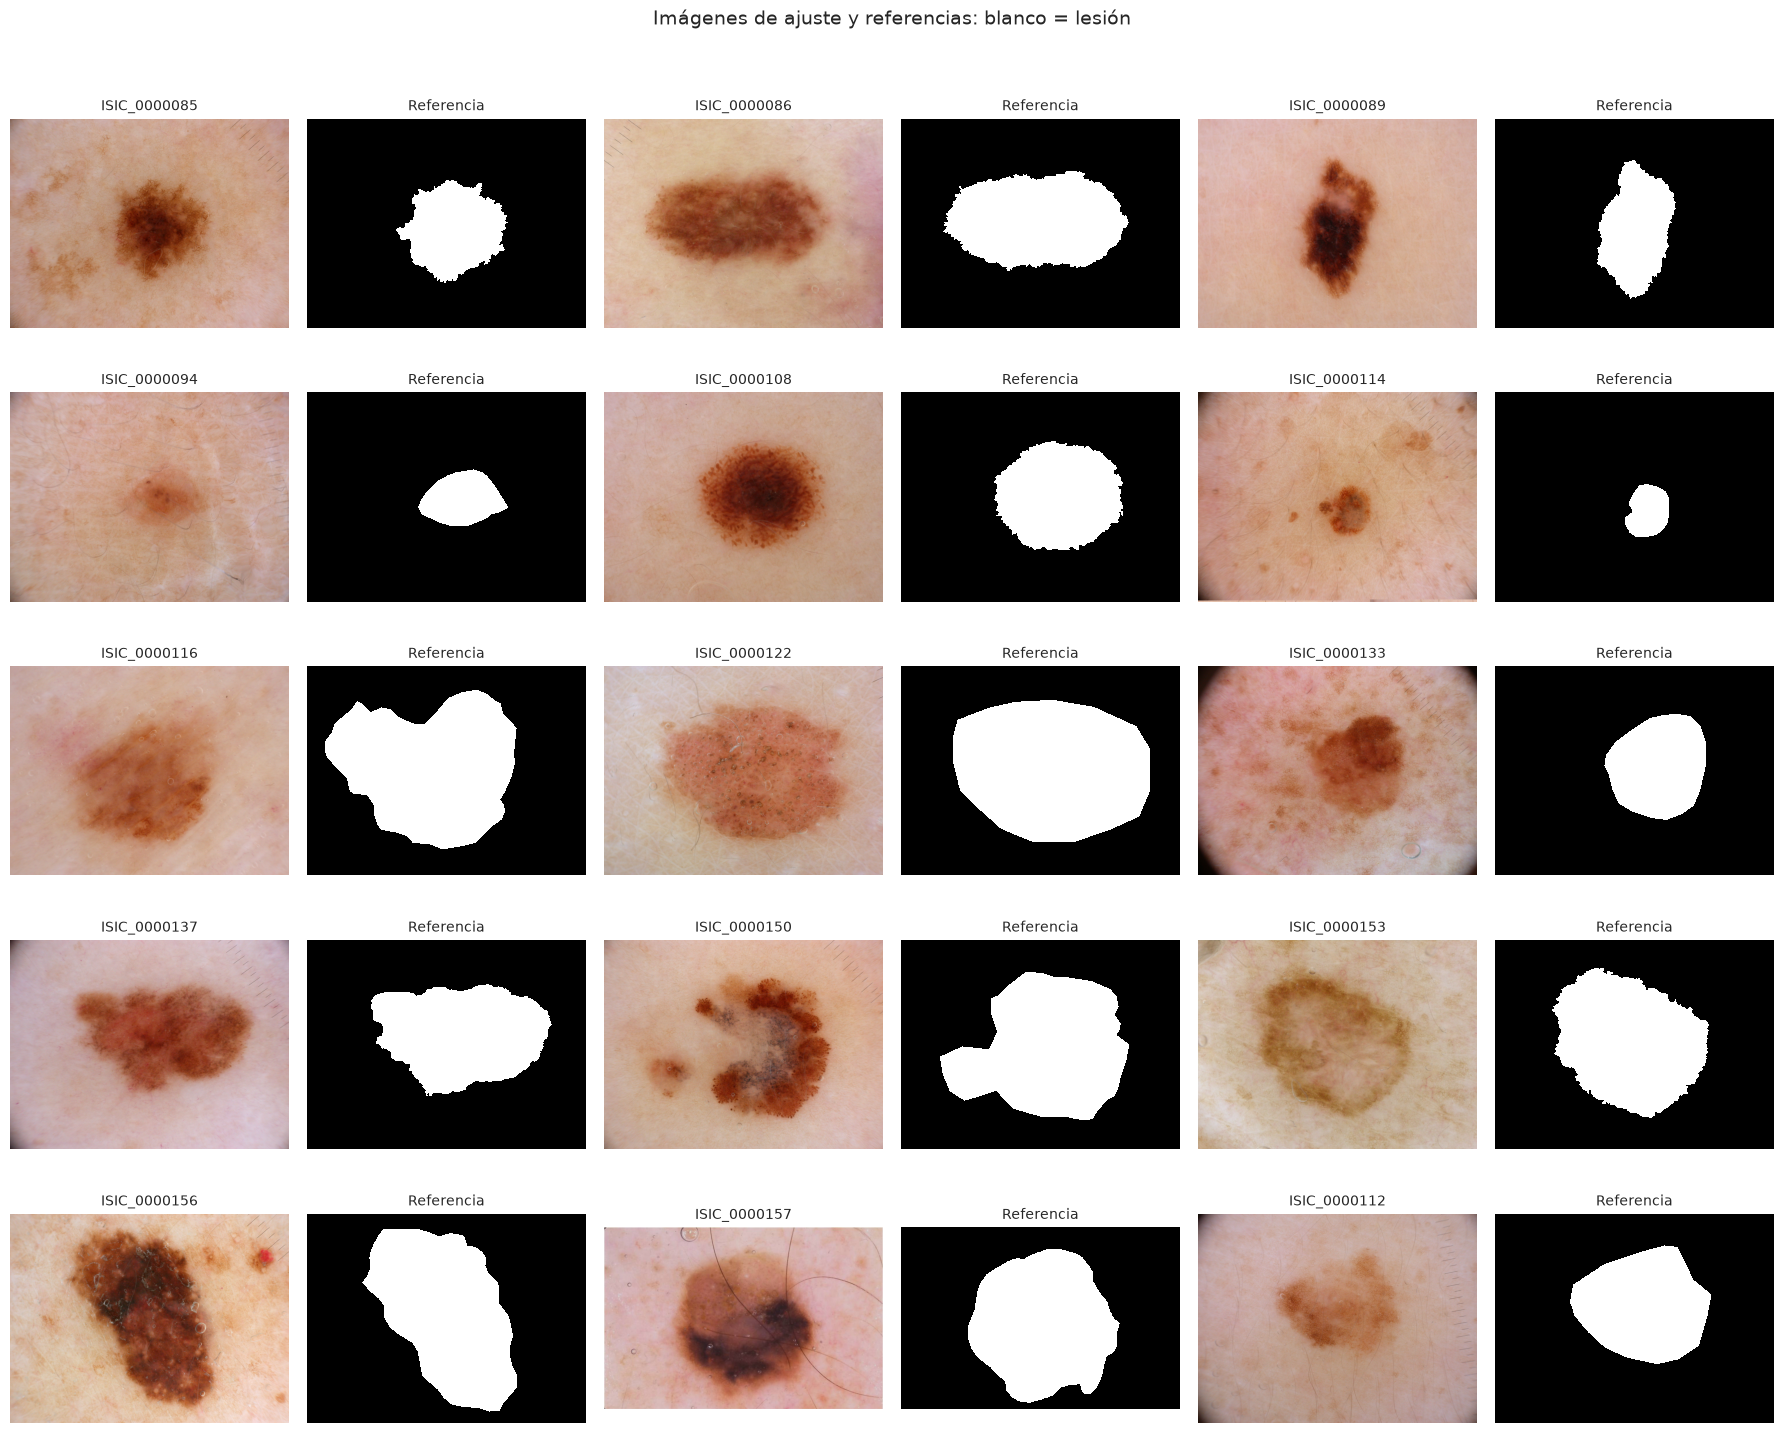

In [7]:
filas_calidad = []
for identificador, par in ajuste.items():
    imagen, mascara = par["imagen"], par["mascara_original"]
    alto, ancho = mascara.shape
    filas_calidad.append({
        "imagen": identificador,
        "ancho": ancho,
        "alto": alto,
        "pixeles": alto * ancho,
        "tipo_imagen": str(imagen.dtype),
        "tipo_mascara": str(mascara.dtype),
        "valores_mascara": str(np.unique(mascara).tolist()),
        "lesion_%": 100 * np.mean(mascara == 255),
        "dimensiones_coinciden": imagen.shape[:2] == mascara.shape,
    })

calidad_ajuste = pd.DataFrame(filas_calidad).set_index("imagen")
display(calidad_ajuste.round({"lesion_%": 2}))
print("Total de píxeles de ajuste:", f"{calidad_ajuste['pixeles'].sum():,}")
print("Referencias vacías:", int((calidad_ajuste["lesion_%"] == 0).sum()))
print("Referencias que ocupan toda la imagen:", int((calidad_ajuste["lesion_%"] == 100).sum()))

# Cada pareja de columnas presenta una imagen y su máscara de referencia.
fig, ejes = plt.subplots(5, 6, figsize=(18, 15))
for indice, (identificador, par) in enumerate(ajuste.items()):
    fila, columna = indice // 3, 2 * (indice % 3)
    ejes[fila, columna].imshow(par["imagen"])
    ejes[fila, columna].set_title(identificador, fontsize=10)
    ejes[fila, columna + 1].imshow(par["mascara_original"], cmap="gray", vmin=0, vmax=255,
                                 interpolation="nearest")
    ejes[fila, columna + 1].set_title("Referencia", fontsize=10)
for eje in ejes.flat:
    eje.axis("off")
fig.suptitle("Imágenes de ajuste y referencias: blanco = lesión", fontsize=14)
plt.tight_layout(rect=(0, 0, 1, .97))
plt.show()


**Interpretación:**

Se cargaron los **15 pares de ajuste**, sin pares faltantes ni ambigüedad de nombres. Todas las imágenes y máscaras son `uint8`; las referencias contienen únicamente 0 y 255, tienen las mismas dimensiones que su imagen y ninguna está vacía ni cubre toda la imagen. Estas comprobaciones verifican compatibilidad estructural, pero no prueban por sí solas la exactitud de los contornos dibujados por los especialistas.

Doce imágenes tienen resolución de **2048 × 1536**, dos (`ISIC_0000086` e `ISIC_0000153`) de **2592 × 1944**, y una (`ISIC_0000157`) de **963 × 629**. En total suman **48.432.159 píxeles**. La diferencia de resolución es relevante para el costo de K-medias; una posible reducción deberá justificarse en la sección 4 y aplicarse de forma coherente a imágenes y referencias, sin deformar innecesariamente su geometría.

La proporción de lesión varía entre **3,15% en `ISIC_0000114`** y **39,01% en `ISIC_0000122`**. Por tanto, no puede suponerse que el grupo más grande corresponda siempre a la lesión. Esta variabilidad también respalda calcular Dice por imagen y luego promediar, para que las imágenes de mayor resolución no dominen la comparación de configuraciones.

La inspección visual muestra dificultades distintas:

- **Contraste y color:** `ISIC_0000094` presenta una región de lesión clara y poco contrastada; `ISIC_0000150` incluye áreas claras, marrones y grisáceas dentro de la referencia. Estos ejemplos sugieren que la lesión podría compartir colores con el fondo o dividirse en varios grupos.
- **Vello y marcas:** `ISIC_0000157` contiene pelos oscuros que cruzan la lesión y el fondo; `ISIC_0000114` presenta otras zonas pigmentadas fuera de la referencia y marcas en la periferia. Un criterio basado únicamente en oscuridad podría incluir píxeles ajenos a la lesión.
- **Bordes e iluminación:** `ISIC_0000133` presenta una esquina oscura fuera de la región señalada. Esto puede competir con la lesión en una representación basada en RGB.

Estas observaciones son hipótesis sobre posibles dificultades, no resultados del método: se contrastarán con los experimentos de ajuste. En esta sección no se han abierto imágenes ni máscaras de prueba, ni se han aplicado correcciones, normalización, binarización o cambios de resolución a los arreglos cargados.

# 4. Pipeline de preparación y representación
**Actividad 1 · 10%.**

Se construye un pipeline de Scikit-learn con dos etapas: reducción de la imagen y representación de sus píxeles. Las máscaras se preparan por separado: nunca se entregan al pipeline como características ni como etiquetas de entrenamiento.

## 4.1 Resolución de trabajo
Se fija un **lado mayor de 128 píxeles**, conservando la proporción original y sin ampliar imágenes más pequeñas. Esto permite explorar las 1.050 combinaciones imagen/pesos/K obligatorias con un costo manejable. Es una decisión computacional inicial, no una resolución demostrada como óptima. Puede perder bordes finos y detalles pequeños; los resultados se evaluarán a esta resolución reducida y esta limitación se explicitará. La regla se mantendrá fija para todas las configuraciones y para la evaluación final.

La imagen RGB se reduce con interpolación bilineal. La máscara correspondiente utiliza **vecino más cercano**, con exactamente las mismas dimensiones de destino, y luego se convierte de 0/255 a 0/1. No se recorta, gira ni elimina contenido.

## 4.2 Representación de píxeles
Para una imagen de alto H y ancho W se obtiene una matriz de tamaño `(H·W, 5)`:

- Color: dividir R, G y B por 255 para llevar cada canal a [0,1].
- Posición: `x = columna/(W−1)` e `y = fila/(H−1)`; si una dimensión mide un píxel, su coordenada es 0.
- Ponderación: multiplicar los tres canales por β y las dos coordenadas por λ.

El aplanamiento recorre las filas de izquierda a derecha y luego de arriba abajo (`order="C"`), el mismo orden que se usará para las referencias y para reconstruir los grupos. Los pesos son no negativos y no pueden ser ambos cero. Se modifican con `set_params`, sin reescribir el transformador.

Los valores **antes de ponderar** están en [0,1]; los ponderados pueden superar 1 cuando los pesos sean mayores que 1. No se aplica después un escalador que anule su efecto. En esta sección se usan pesos unitarios solo para verificar la representación; la comparación y elección de pesos se realizará más adelante.


In [8]:
LADO_MAXIMO = 128


def dimensiones_destino(alto, ancho, lado_maximo):
    if not isinstance(lado_maximo, (int, np.integer)) or lado_maximo < 1:
        raise ValueError("lado_maximo debe ser un entero positivo")
    escala = min(1.0, lado_maximo / max(alto, ancho))
    return max(1, round(ancho * escala)), max(1, round(alto * escala))  # ancho, alto


class PrepararImagen(TransformerMixin, BaseEstimator):
    def __init__(self, lado_maximo=128):
        self.lado_maximo = lado_maximo

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        imagen = np.asarray(X)
        if imagen.ndim != 3 or imagen.shape[2] != 3 or imagen.dtype != np.uint8:
            raise ValueError("Se espera una imagen RGB uint8 con forma (alto, ancho, 3)")
        if min(imagen.shape[:2]) < 1:
            raise ValueError("La imagen no puede estar vacía")
        destino = dimensiones_destino(*imagen.shape[:2], self.lado_maximo)
        return np.asarray(Image.fromarray(imagen).resize(destino, Image.Resampling.BILINEAR))


class RepresentarPixeles(TransformerMixin, BaseEstimator):
    def __init__(self, beta=1.0, lambda_=1.0):
        self.beta = beta
        self.lambda_ = lambda_

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        pesos = np.asarray([self.beta, self.lambda_], dtype=float)
        if not np.isfinite(pesos).all() or (pesos < 0).any() or not pesos.any():
            raise ValueError("Los pesos deben ser finitos, no negativos y no ambos cero")
        imagen = np.asarray(X)
        if imagen.ndim != 3 or imagen.shape[2] != 3 or imagen.dtype != np.uint8:
            raise ValueError("Se espera una imagen RGB uint8")
        alto, ancho, _ = imagen.shape
        if min(alto, ancho) < 1:
            raise ValueError("La imagen no puede estar vacía")
        color = imagen.reshape(-1, 3, order="C").astype(np.float64) / 255.0
        x, y = np.meshgrid(np.linspace(0, 1, ancho), np.linspace(0, 1, alto))
        return np.column_stack([
            pesos[0] * color,
            pesos[1] * x.ravel(order="C"),
            pesos[1] * y.ravel(order="C"),
        ])


def preparar_mascara(mascara_original, lado_maximo=LADO_MAXIMO):
    mascara = np.asarray(mascara_original)
    if mascara.ndim != 2 or min(mascara.shape) < 1 or not np.isin(mascara, [0, 255]).all():
        raise ValueError("Se espera una máscara original 2D con valores 0 y 255")
    destino = dimensiones_destino(*mascara.shape, lado_maximo)
    reducida = np.asarray(Image.fromarray(mascara).resize(destino, Image.Resampling.NEAREST))
    return (reducida == 255).astype(np.uint8)


pipeline_preparacion = Pipeline([
    ("imagen", PrepararImagen(lado_maximo=LADO_MAXIMO)),
    ("pixeles", RepresentarPixeles(beta=1.0, lambda_=1.0)),
])

# Preparar solo ajuste. Las referencias permanecen fuera del pipeline.
ajuste_preparado = {}
filas_preparacion = []
for identificador, par in ajuste.items():
    rgb = pipeline_preparacion.named_steps["imagen"].fit_transform(par["imagen"])
    referencia = preparar_mascara(par["mascara_original"])
    X = pipeline_preparacion.fit_transform(par["imagen"])
    assert rgb.shape[:2] == referencia.shape
    assert X.shape == (referencia.size, 5)
    assert np.isfinite(X).all() and X.min() >= 0 and X.max() <= 1
    assert set(np.unique(referencia)) == {0, 1}
    ajuste_preparado[identificador] = {"imagen": rgb, "referencia": referencia}
    filas_preparacion.append({
        "imagen": identificador,
        "ancho": rgb.shape[1], "alto": rgb.shape[0], "pixeles": referencia.size,
        "caracteristicas": X.shape[1],
        "lesion_original_%": 100 * np.mean(par["mascara_original"] == 255),
        "lesion_reducida_%": 100 * referencia.mean(),
    })

resumen_preparacion = pd.DataFrame(filas_preparacion).set_index("imagen")
resumen_preparacion["cambio_area_pp"] = (
    resumen_preparacion["lesion_reducida_%"] - resumen_preparacion["lesion_original_%"]
)
display(resumen_preparacion.round(3))
print("Píxeles originales:", f"{calidad_ajuste['pixeles'].sum():,}")
print("Píxeles de trabajo:", f"{resumen_preparacion['pixeles'].sum():,}")
print("Reducción del número de píxeles:",
      f"{calidad_ajuste['pixeles'].sum() / resumen_preparacion['pixeles'].sum():.2f} veces")

# Verificación de orden espacial y parametrización con un ejemplo controlado.
ejemplo = np.array([[[0, 0, 0], [255, 0, 0]],
                    [[0, 255, 0], [0, 0, 255]]], dtype=np.uint8)
esperado = np.array([[0, 0, 0, 0, 0], [1, 0, 0, 1, 0],
                     [0, 1, 0, 0, 1], [0, 0, 1, 1, 1]], dtype=float)
assert np.array_equal(pipeline_preparacion.fit_transform(ejemplo), esperado)
pipeline_preparacion.set_params(pixeles__beta=1, pixeles__lambda_=0)
assert np.array_equal(pipeline_preparacion.fit_transform(ejemplo), esperado * [1, 1, 1, 0, 0])
pipeline_preparacion.set_params(pixeles__beta=0, pixeles__lambda_=1)
assert np.array_equal(pipeline_preparacion.fit_transform(ejemplo), esperado * [0, 0, 0, 1, 1])
pipeline_preparacion.set_params(pixeles__beta=1, pixeles__lambda_=1)
print("Verificaciones correctas: cinco características, orden espacial, solo color y solo posición.")


,ancho,alto,pixeles,caracteristicas,lesion_original_%,lesion_reducida_%,cambio_area_pp
imagen,,,,,,,
ISIC_0000085,128,96,12288,5,12.654,12.598,-0.056
ISIC_0000086,128,96,12288,5,23.361,23.324,-0.038
ISIC_0000089,128,96,12288,5,12.141,12.118,-0.023
ISIC_0000094,128,96,12288,5,5.944,5.949,0.005
ISIC_0000108,128,96,12288,5,18.490,18.384,-0.106
ISIC_0000114,128,96,12288,5,3.149,3.133,-0.016
ISIC_0000116,128,96,12288,5,36.076,36.117,0.041
ISIC_0000122,128,96,12288,5,39.008,38.973,-0.035
ISIC_0000133,128,96,12288,5,14.162,14.152,-0.010


Píxeles originales: 48,432,159
Píxeles de trabajo: 182,784
Reducción del número de píxeles: 264.97 veces
Verificaciones correctas: cinco características, orden espacial, solo color y solo posición.


**Justificación e interpretación:**

La preparación reduce los **48.432.159 píxeles originales a 182.784 píxeles de trabajo**, aproximadamente **265 veces menos**. Catorce imágenes quedan en 128 × 96 y `ISIC_0000157` en 128 × 84, respetando la proporción original salvo el redondeo a dimensiones enteras. Esto reduce el costo de los ajustes repetidos sin imponer un cuadrado que deforme las imágenes.

Todas las referencias preparadas conservan valores **0 y 1**, incluyen tanto lesión como fondo y coinciden en dimensiones con su imagen reducida. El mayor cambio absoluto de proporción de lesión es **0,1065 puntos porcentuales**, en `ISIC_0000108`. Este cambio pequeño en área global no demuestra que los contornos finos se conserven: una evaluación a baja resolución puede ocultar errores pequeños de borde. No se afirma que esta resolución sea óptima ni que los resultados equivalgan a una segmentación a resolución original.

Se verificó con un ejemplo de colores y posiciones conocidos que las filas de la matriz corresponden al recorrido espacial declarado. También se comprobó que **λ = 0 elimina exclusivamente las coordenadas** y **β = 0 elimina exclusivamente los colores**. Los pesos se parametrizan en el paso `pixeles` del pipeline; no es necesario modificar su implementación para explorar combinaciones. Los pesos unitarios de esta sección son una comprobación y no una configuración final seleccionada.

Las coordenadas se normalizan por las dimensiones de cada imagen, por lo que expresan posición relativa. Los colores se normalizan por 255, conservando sus diferencias entre píxeles. La distancia al cuadrado utilizada posteriormente por K-medias será la suma de las diferencias de color al cuadrado ponderadas por β² y las diferencias de posición al cuadrado ponderadas por λ². Por ello importan los pesos relativos y no deben neutralizarse con un escalado posterior.

Las referencias se mantienen fuera del pipeline para evitar que influyan en las características o en el agrupamiento. Las matrices de características y las referencias comparten dimensiones y orden de aplanamiento. No se han ajustado modelos de agrupación ni consultado imágenes de prueba en esta sección.

# 5. Agrupación y selección de K
**Actividad 2 · 10%.**

## 5.1 Combinaciones de pesos y reproducibilidad
Se exploran las diez combinaciones discutidas: solo color `(1, 0)`, ocho mixtas `(1, λ)` con λ en `{0,05; 0,1; 0,25; 0,5; 1; 2; 4; 8}`, y solo posición `(0, 1)`. Cubren distintas razones λ/β, desde ignorar la posición hasta darle una influencia fuerte. No incluyen pares proporcionales redundantes. Son una rejilla de exploración, no una configuración final seleccionada.

Para cada una de las 15 imágenes se evalúan las diez combinaciones y **K = 2,…,8**, en total **1.050 ajustes**. K-medias utiliza todos los píxeles de la imagen preparada, inicialización `k-means++`, diez inicializaciones y semilla 42. Se fija `algorithm="lloyd"`, `max_iter=300` y `tol=1e-4` para documentar la ejecución.

La silueta se calcula sobre **1.000 píxeles uniformes sin reemplazo por imagen**, con semilla 42 (o todos si hubiera menos de 1.000). Se reutilizan exactamente los mismos índices dentro de cada imagen para todos los pesos y K, evitando que las comparaciones cambien por otra muestra. No se utiliza la referencia para muestrear ni agrupar.

## 5.2 Regla de selección
Se elige el K con mayor silueta para cada pareja imagen/pesos; ante empate numérico exacto se elige el menor K. Si la muestra tiene menos de dos grupos, o tantos grupos como píxeles, su silueta se registra como no definida. Si ningún K es evaluable, se detiene la ejecución para revisar el caso. Se conserva la exploración completa y los grupos del K elegido para las siguientes secciones. No se calcula Dice ni se selecciona todavía la mejor combinación de pesos.


,configuracion,beta,lambda,razon_lambda_beta
0,C01,1.0,0.00,0.00
1,C02,1.0,0.05,0.05
2,C03,1.0,0.10,0.10
3,C04,1.0,0.25,0.25
4,C05,1.0,0.50,0.50
5,C06,1.0,1.00,1.00
6,C07,1.0,2.00,2.00
7,C08,1.0,4.00,4.00
8,C09,1.0,8.00,8.00
9,C10,0.0,1.00,inf


configuracion,C01,C02,C03,C04,C05,C06,C07,C08,C09,C10
imagen,,,,,,,,,,
ISIC_0000085,2,2,2,2,2,5,5,5,4,4
ISIC_0000086,2,2,2,2,2,5,5,5,4,4
ISIC_0000089,2,2,2,2,2,5,5,5,4,4
ISIC_0000094,2,2,2,4,5,5,4,4,4,4
ISIC_0000108,2,2,2,2,2,5,5,5,4,4
ISIC_0000112,2,2,2,2,5,5,5,4,4,4
ISIC_0000114,2,2,2,2,5,5,4,4,4,4
ISIC_0000116,2,2,2,2,5,5,5,5,4,4
ISIC_0000122,2,2,2,2,5,5,5,4,4,4


,silueta_media,silueta_min,silueta_max
configuracion,,,
C01,0.753299,0.652589,0.866186
C02,0.742576,0.629374,0.857372
C03,0.719014,0.586254,0.838484
C04,0.617996,0.356987,0.762965
C05,0.490764,0.361999,0.627653
C06,0.433313,0.372056,0.464522
C07,0.418385,0.384658,0.447308
C08,0.395756,0.384901,0.410429
C09,0.391717,0.379421,0.394941


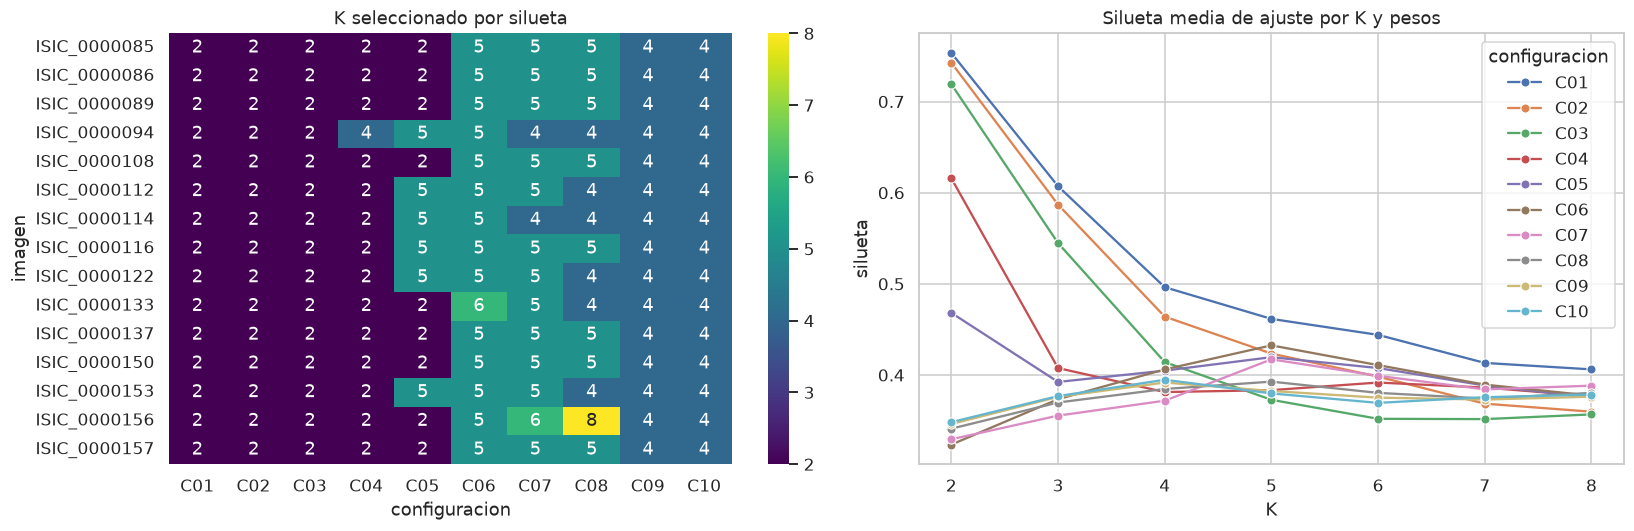

Exploración completada: ISIC_0000085
Exploración completada: ISIC_0000086
Exploración completada: ISIC_0000089
Exploración completada: ISIC_0000094
Exploración completada: ISIC_0000108
Exploración completada: ISIC_0000114
Exploración completada: ISIC_0000116
Exploración completada: ISIC_0000122
Exploración completada: ISIC_0000133
Exploración completada: ISIC_0000137
Exploración completada: ISIC_0000150
Exploración completada: ISIC_0000153
Exploración completada: ISIC_0000156
Exploración completada: ISIC_0000157
Exploración completada: ISIC_0000112
Tiempo total: 63.5 segundos
Ajustes registrados: 1050; selecciones de K: 150
Siluetas no definidas: 0


In [5]:
from sklearn.base import clone
from threadpoolctl import threadpool_limits

N_SILUETA = 1000
N_INIT = 10
COMBINACIONES_PESOS = [
    (1.0, 0.0), (1.0, 0.05), (1.0, 0.1), (1.0, 0.25), (1.0, 0.5),
    (1.0, 1.0), (1.0, 2.0), (1.0, 4.0), (1.0, 8.0), (0.0, 1.0),
]
configuraciones_pesos = pd.DataFrame(COMBINACIONES_PESOS, columns=["beta", "lambda"])
configuraciones_pesos.insert(0, "configuracion", [f"C{i:02d}" for i in range(1, 11)])
configuraciones_pesos["razon_lambda_beta"] = [l / b if b else np.inf for b, l in COMBINACIONES_PESOS]
assert configuraciones_pesos["razon_lambda_beta"].nunique() == 10
display(configuraciones_pesos)


def seleccionar_k_imagen(imagen, beta, lambda_):
    # La función recibe solo RGB y pesos: no recibe una máscara de referencia.
    preparacion = clone(pipeline_preparacion).set_params(
        pixeles__beta=beta, pixeles__lambda_=lambda_)
    X = preparacion.fit_transform(imagen)
    forma = preparacion.named_steps["imagen"].transform(imagen).shape[:2]
    indices = np.random.default_rng(RANDOM_STATE).choice(
        len(X), size=min(N_SILUETA, len(X)), replace=False)
    filas, mejor = [], None
    for k in K_CANDIDATOS:
        inicio = perf_counter()
        modelo = KMeans(n_clusters=k, init="k-means++", n_init=N_INIT,
                        random_state=RANDOM_STATE, algorithm="lloyd", max_iter=300, tol=1e-4)
        # Pipeline completo: imagen -> representación ponderada -> K-medias.
        pipeline_modelo = Pipeline([
            ("imagen", clone(preparacion.named_steps["imagen"])),
            ("pixeles", clone(preparacion.named_steps["pixeles"])),
            ("kmeans", modelo),
        ])
        grupos = pipeline_modelo.fit_predict(imagen)
        etiquetas_muestra = grupos[indices]
        n_grupos = np.unique(etiquetas_muestra).size
        silueta = float(silhouette_score(X[indices], etiquetas_muestra)) if 1 < n_grupos < len(indices) else np.nan
        filas.append({"K": k, "silueta": silueta, "n_muestra": len(indices),
                      "grupos_en_muestra": n_grupos, "iteraciones": modelo.n_iter_,
                      "segundos": perf_counter() - inicio})
        # El recorrido ascendente conserva el menor K si las siluetas empatan.
        if np.isfinite(silueta) and (mejor is None or silueta > mejor["silueta"]):
            mejor = {"K": int(k), "silueta": silueta, "grupos": grupos.reshape(forma, order="C"),
                     "modelo": modelo, "preparacion": preparacion, "pipeline": pipeline_modelo}
    if mejor is None:
        raise ValueError("No se pudo calcular silueta válida para ningún K")
    return mejor, pd.DataFrame(filas)


filas_exploracion, filas_seleccion = [], []
agrupaciones_ajuste = {}
inicio_exploracion = perf_counter()
# Un hilo evita sobrecosto de paralelización en matrices pequeñas y uso excesivo de CPU.
with threadpool_limits(limits=1):
    for identificador in IDS_AJUSTE:
        for config in configuraciones_pesos.to_dict("records"):
            mejor, tabla_k = seleccionar_k_imagen(
                ajuste[identificador]["imagen"], config["beta"], config["lambda"])
            filas_exploracion.append(tabla_k.assign(
                imagen=identificador, configuracion=config["configuracion"],
                beta=config["beta"], **{"lambda": config["lambda"]}))
            agrupaciones_ajuste[(identificador, config["configuracion"])] = mejor
            filas_seleccion.append({"imagen": identificador, "configuracion": config["configuracion"],
                                   "beta": config["beta"], "lambda": config["lambda"],
                                   "K": mejor["K"], "silueta": mejor["silueta"]})
        print("Exploración completada:", identificador, flush=True)

exploracion_k = pd.concat(filas_exploracion, ignore_index=True)
seleccion_k = pd.DataFrame(filas_seleccion)
assert len(exploracion_k) == 15 * 10 * 7
assert len(seleccion_k) == 15 * 10
assert exploracion_k.groupby(["imagen", "configuracion"])["K"].nunique().eq(7).all()
assert exploracion_k["n_muestra"].eq(N_SILUETA).all()
print(f"Tiempo total: {perf_counter() - inicio_exploracion:.1f} segundos")
print(f"Ajustes registrados: {len(exploracion_k)}; selecciones de K: {len(seleccion_k)}")
print("Siluetas no definidas:", int(exploracion_k["silueta"].isna().sum()))
display(seleccion_k.pivot(index="imagen", columns="configuracion", values="K"))
display(seleccion_k.groupby("configuracion").agg(
    silueta_media=("silueta", "mean"), silueta_min=("silueta", "min"),
    silueta_max=("silueta", "max")))

fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(seleccion_k.pivot(index="imagen", columns="configuracion", values="K"),
            annot=True, fmt="d", cmap="viridis", vmin=2, vmax=8, ax=ejes[0])
ejes[0].set_title("K seleccionado por silueta")
# Promedio entre imágenes solo para resumir; la selección se hace por imagen.
curvas = exploracion_k.groupby(["configuracion", "K"], as_index=False)["silueta"].mean()
sns.lineplot(data=curvas, x="K", y="silueta", hue="configuracion", marker="o", ax=ejes[1])
ejes[1].set_title("Silueta media de ajuste por K y pesos")
ejes[1].set_xticks(K_CANDIDATOS)
plt.tight_layout()
plt.show()


**Interpretación:**

Se ejecutaron los **1.050 ajustes** previstos y se obtuvieron **150 selecciones de K**, una por imagen y combinación de pesos. Todas las siluetas se calcularon sobre las mismas 1.000 posiciones reproducibles dentro de cada imagen; hubo **0 siluetas no definidas**. **0 ajustes** alcanzaron el límite de 300 iteraciones. Este último control no demuestra que se haya encontrado un óptimo global: K-medias puede converger a mínimos locales, por lo que se utilizan diez inicializaciones.

La distribución de selecciones fue: **K=2: 68 casos, K=4: 39 casos, K=5: 40 casos, K=6: 2 casos, K=8: 1 casos**. La silueta de las configuraciones seleccionadas por imagen varió entre **0.3570 y 0.8662**. La tabla y el mapa de calor muestran los valores por imagen; las curvas resumen el promedio entre imágenes y no sustituyen la selección individual.

Para solo color (C01), la silueta media de los K elegidos fue **0.7533**; para solo posición (C10), **0.3947**. En solo posición, imágenes de igual resolución preparada tienen la misma nube de coordenadas y la misma muestra, por lo que el agrupamiento no contiene información del aspecto de la lesión. Una silueta favorable en ese extremo solo describe separación espacial, no calidad de segmentación.

No se decide aquí qué pesos producen la mejor máscara. La silueta mide cohesión y separación en el espacio ponderado; cambiar los pesos cambia esa geometría y no garantiza delimitar la lesión. En las secciones 6 y 8 se construirá la máscara automática y se comparará por Dice promedio en ajuste. No se han utilizado referencias para elegir K ni se han consultado imágenes de prueba. `exploracion_k` conserva los siete valores evaluados en cada caso y `agrupaciones_ajuste` conserva los grupos ganadores para continuar el análisis.

# 6. Construcción de la máscara
**Actividad 3 · 15%.**

## 6.1 Del agrupamiento a la segmentación
El pipeline de preparación se definió en la sección 4. En la función `seleccionar_k_imagen` de la sección 5 se construye el **pipeline completo del modelo**: `imagen → píxeles ponderados → K-medias`. Cada candidato se ajusta con `fit_predict`; se conserva el pipeline del K ganador para cada imagen y combinación de pesos.

Sus salidas son identificadores de grupo, no etiquetas de lesión. Por ejemplo, el grupo 0 no significa siempre lesión: la numeración es arbitraria. Esta sección añade una regla posterior que convierte esos grupos en una máscara binaria. La regla recibe solo la imagen preparada y los grupos, nunca la máscara de referencia.

## 6.2 Criterio automático: grupo de menor intensidad media
Se propone como primera hipótesis que la región de lesión es, en promedio, más oscura que la piel circundante. Para cada grupo se calcula la intensidad media de sus píxeles como la media de los tres canales RGB normalizados. Se selecciona el grupo de menor intensidad y se asigna **1 a todos sus píxeles y 0 al resto**.

La media RGB es una medida sencilla de intensidad, no una medida perceptual calibrada de luminosidad. Se calcula sobre los colores de la imagen preparada, antes de aplicar β: así el criterio conserva su definición incluso con β = 0, cuando K-medias agrupa solo por posición.

La regla es la misma para todas las imágenes y combinaciones, no utiliza umbrales ajustados por imagen y no escoge el grupo por superposición con la referencia. En un empate exacto se selecciona el grupo con mayor número de píxeles; si persiste, el de menor identificador. No se aplican filtros morfológicos, relleno de huecos ni selección de componentes en esta primera versión. La calidad de esta hipótesis se evaluará por Dice en la sección 8; aún no se declara como una solución validada.


,grupo,n_pixeles,intensidad_media,seleccionado,imagen,configuracion,criterio
0,1,1300,0.2966,True,ISIC_0000085,C01,grupo_oscuro
1,0,10988,0.6318,False,ISIC_0000085,C01,grupo_oscuro
33,1,2514,0.3634,True,ISIC_0000086,C01,grupo_oscuro
34,0,9774,0.6953,False,ISIC_0000086,C01,grupo_oscuro
66,1,1329,0.2712,True,ISIC_0000089,C01,grupo_oscuro
67,0,10959,0.7076,False,ISIC_0000089,C01,grupo_oscuro


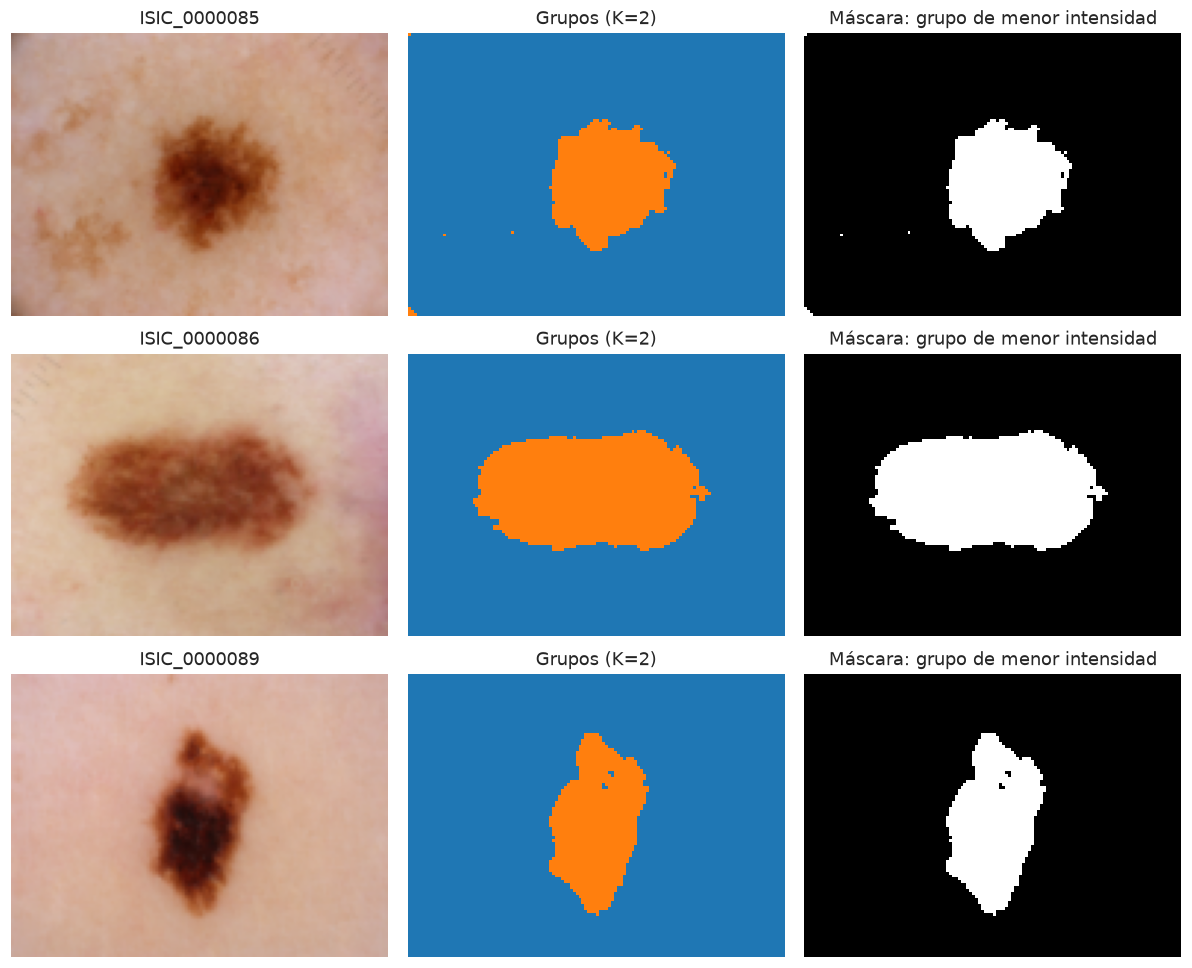

Máscaras de ajuste construidas: 150
Referencias utilizadas para escoger grupos: ninguna.


In [6]:
def construir_mascara_oscura(imagen, grupos):
    """Devuelve máscara y estadísticas sin recibir ni consultar la referencia."""
    rgb = np.asarray(imagen)
    etiquetas = np.asarray(grupos)
    if rgb.ndim != 3 or rgb.shape[2] != 3 or rgb.dtype != np.uint8:
        raise ValueError("Se espera una imagen RGB uint8 preparada")
    if etiquetas.ndim != 2 or etiquetas.shape != rgb.shape[:2]:
        raise ValueError("Los grupos deben coincidir con las dimensiones de la imagen")
    if not np.issubdtype(etiquetas.dtype, np.integer) or etiquetas.size == 0:
        raise ValueError("Se esperan identificadores enteros y una imagen no vacía")

    intensidad = rgb.astype(np.float64).mean(axis=2) / 255.0
    filas = []
    for grupo in np.unique(etiquetas):
        pertenece = etiquetas == grupo
        filas.append({"grupo": int(grupo), "n_pixeles": int(pertenece.sum()),
                      "intensidad_media": float(intensidad[pertenece].mean())})
    estadisticas = pd.DataFrame(filas).sort_values(
        ["intensidad_media", "n_pixeles", "grupo"],
        ascending=[True, False, True], kind="stable").reset_index(drop=True)
    grupo_lesion = int(estadisticas.iloc[0]["grupo"])
    mascara = (etiquetas == grupo_lesion).astype(np.uint8)
    estadisticas["seleccionado"] = estadisticas["grupo"] == grupo_lesion
    return mascara, estadisticas


# Se conserva un registro para poder comparar criterios en la sección 8 si se añaden otros.
CRITERIOS_MASCARA = {"grupo_oscuro": construir_mascara_oscura}
mascaras_ajuste = {}
filas_grupos = []
for (identificador, configuracion), agrupacion in agrupaciones_ajuste.items():
    imagen = ajuste_preparado[identificador]["imagen"]
    for nombre_criterio, funcion in CRITERIOS_MASCARA.items():
        mascara, estadisticas = funcion(imagen, agrupacion["grupos"])
        assert mascara.shape == imagen.shape[:2]
        assert mascara.dtype == np.uint8 and np.isin(mascara, [0, 1]).all()
        assert estadisticas["seleccionado"].sum() == 1
        mascaras_ajuste[(identificador, configuracion, nombre_criterio)] = mascara
        filas_grupos.append(estadisticas.assign(
            imagen=identificador, configuracion=configuracion, criterio=nombre_criterio))

estadisticas_grupos = pd.concat(filas_grupos, ignore_index=True)
print("Máscaras de ajuste construidas:", len(mascaras_ajuste))
print("Referencias utilizadas para escoger grupos: ninguna.")

# Ejemplos predeterminados: las primeras tres imágenes y solo color (C01).
# No se eligen por su Dice ni por comparación con la referencia.
configuracion_ejemplo = "C01"
ids_ejemplo = IDS_AJUSTE[:3]
display(estadisticas_grupos[
    estadisticas_grupos["imagen"].isin(ids_ejemplo) &
    (estadisticas_grupos["configuracion"] == configuracion_ejemplo)
].round({"intensidad_media": 4}))

fig, ejes = plt.subplots(len(ids_ejemplo), 3, figsize=(11, 9), squeeze=False)
for fila, identificador in enumerate(ids_ejemplo):
    rgb = ajuste_preparado[identificador]["imagen"]
    grupos = agrupaciones_ajuste[(identificador, configuracion_ejemplo)]["grupos"]
    mascara = mascaras_ajuste[(identificador, configuracion_ejemplo, "grupo_oscuro")]
    ejes[fila, 0].imshow(rgb)
    ejes[fila, 0].set_title(identificador)
    ejes[fila, 1].imshow(grupos, cmap="tab10", vmin=0, vmax=9, interpolation="nearest")
    ejes[fila, 1].set_title(f"Grupos (K={np.unique(grupos).size})")
    ejes[fila, 2].imshow(mascara, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ejes[fila, 2].set_title("Máscara: grupo de menor intensidad")
for eje in ejes.flat:
    eje.axis("off")
plt.tight_layout()
plt.show()


**Justificación y límites del criterio:**

La exploración de ajuste mostró diferencias de color entre lesiones y piel, por lo que la intensidad es una hipótesis inicial sencilla e interpretable. La elección se basa en una característica del grupo y no en su identificador. El promedio evita que el puntaje sea directamente una suma dependiente de su tamaño; el tamaño solo se utiliza como desempate.

El criterio **no garantiza identificar toda la lesión**: si K-medias separa sus zonas claras y oscuras, elegir un único grupo puede excluir partes de la referencia. También puede escoger vello, marcas o bordes oscuros. En `ISIC_0000094` el bajo contraste observado puede dificultar la separación; en `ISIC_0000150` la variedad de colores puede fragmentar la lesión; y en `ISIC_0000133` la esquina oscura puede competir con ella. Estas son hipótesis que deben contrastarse en la evaluación de ajuste, no conclusiones de desempeño.

En la configuración de solo posición, los grupos se construyen sin color, pero esta regla posterior sigue utilizando RGB para decidir cuál es lesión. Por ello, «solo posición» describe las características utilizadas por **K-medias**, no la información usada por todo el procedimiento de segmentación. Esta distinción se mantendrá al interpretar las comparaciones.

Las máscaras construidas conservan las dimensiones y el orden de los grupos y contienen únicamente 0 y 1. Las visualizaciones muestran el funcionamiento de la regla sobre ejemplos fijados de antemano, sin usar referencias para elegir grupos ni ejemplos. El Dice y la comparación con las referencias se realizarán en la sección 8, después de completar la actividad de verificación de IAG. No se han consultado imágenes de prueba.

# 7. Verificación obligatoria de IAG
**Actividad pendiente para el compañero responsable. Debe completarse antes de seleccionar la configuración final en la sección 8.**

Esta sección es un experimento: se contrasta una recomendación de IA con las imágenes de ajuste. No es solamente la declaración general de uso de IA de la sección 13 y no sustituye la exploración obligatoria de la sección 5.

## 7.1 Consulta y registro

1. Abrir una **conversación nueva**, sin el contexto de este notebook ni este chat.
2. Describir fotografías dermatoscópicas de lesiones de piel, **sin adjuntar imágenes ni mencionar el nombre del dataset**.
3. Pedir valores concretos de **β, λ y K**, y un **criterio automático para decidir qué grupos son lesión** y construir la máscara. Solicitar explicación de sus supuestos.
4. Conservar el historial con el prompt, la respuesta y las interacciones posteriores. Incluirlo aquí o adjuntarlo a la entrega; registrar herramienta, fecha y ubicación del historial.

Prompt que se puede utilizar en esa nueva conversación:

> Tengo fotografías dermatoscópicas a color de lesiones de piel y quiero delimitar la lesión con K-medias. Cada píxel se representa como [βR, βG, βB, λx, λy], con colores y coordenadas normalizados a [0,1] antes de aplicar los pesos. Sin ver las imágenes, recomienda valores concretos de β, λ y K y un criterio automático para identificar los grupos de lesión y construir una máscara binaria. Explica los supuestos y en qué situaciones podría fallar.

## 7.2 Implementación y prueba de la recomendación

- Registrar literalmente los valores y la regla propuestos; pedir aclaraciones en la misma conversación si no son implementables.
- Usar **solo las 15 imágenes de ajuste**, con el procesamiento acordado en la sección 4. No abrir prueba.
- Implementar y evaluar la recomendación como experimento separado. Si propone K fijo, probar ese K, sin reemplazarlo silenciosamente por el elegido por silueta.
- El criterio que construye la máscara no puede consultar la referencia. Usar la referencia únicamente después para evaluar.
- Presentar tabla por imagen con la configuración aplicada y Dice; añadir V-measure como información complementaria y ejemplos visuales de aciertos y fallos.
- Si se modifica la propuesta, distinguir los resultados de la recomendación original de los de la adaptación propia y justificar los cambios.

## 7.3 Evidencia y análisis crítico

**Por completar por el responsable:** herramienta y fecha; historial; recomendación recibida; código y resultados reales; explicación de en qué imágenes funcionó o falló y por qué la IAG no podía anticiparlo sin observar las imágenes. No inventar respuestas ni resultados.

La sección 13 deberá referenciar esta verificación y declarar los demás usos de IAG y los aportes propios, sin duplicar todo el experimento.


**Análisis de la verificación:** ¿funcionó la recomendación?, ¿en qué acertó y falló?, ¿por qué la IAG no podía anticipar el comportamiento en sus imágenes? Completar con resultados propios.

# 8. Ajuste y selección de la configuración
**Actividad 4 · 10% selección y parte de la presentación de resultados.**

**Estado:** evaluación de ajuste realizada antes de completar la sección 7. El ranking es provisional: no se fija la configuración final ni se evalúa prueba hasta documentar y contrastar la recomendación de IAG.

Se evalúan las diez combinaciones con el criterio `grupo_oscuro` de la sección 6. Se utilizan exclusivamente las 15 referencias de ajuste. Para cada imagen se conserva el K elegido por silueta en la sección 5: no se modifica para mejorar Dice.

Dice compara la máscara binaria estimada con la referencia. V-measure compara los **grupos originales de K-medias** con las etiquetas binarias de referencia. El criterio principal de comparación es la media de los 15 Dice, dando igual peso a cada imagen. Se reportan también dispersión, mínimo, precisión y recall para revisar los fallos. La dispersión es descriptiva, no un intervalo de confianza.

En empates exactos de Dice promedio se utiliza el identificador de configuración y luego el nombre de criterio como orden determinista; V-measure se mantiene como información complementaria.


In [7]:
filas_evaluacion = []
for seleccion in seleccion_k.to_dict("records"):
    identificador = seleccion["imagen"]
    configuracion = seleccion["configuracion"]
    referencia = ajuste_preparado[identificador]["referencia"]
    grupos = agrupaciones_ajuste[(identificador, configuracion)]["grupos"]
    for criterio in CRITERIOS_MASCARA:
        estimada = mascaras_ajuste[(identificador, configuracion, criterio)]
        assert referencia.shape == estimada.shape == grupos.shape
        assert np.isin(referencia, [0, 1]).all() and np.isin(estimada, [0, 1]).all()
        y = referencia.ravel(order="C")
        pred = estimada.ravel(order="C")
        filas_evaluacion.append({
            **seleccion, "criterio": criterio,
            "Dice": f1_score(y, pred, pos_label=1, zero_division=0),
            "V_measure": v_measure_score(y, grupos.ravel(order="C")),
            "precision": precision_score(y, pred, pos_label=1, zero_division=0),
            "recall": recall_score(y, pred, pos_label=1, zero_division=0),
            "FP": int(((pred == 1) & (y == 0)).sum()),
            "FN": int(((pred == 0) & (y == 1)).sum()),
        })
resultados_ajuste = pd.DataFrame(filas_evaluacion)
assert len(resultados_ajuste) == 15 * 10 * len(CRITERIOS_MASCARA)
assert set(resultados_ajuste["imagen"]) == set(IDS_AJUSTE)
assert set(resultados_ajuste["imagen"]).isdisjoint(IDS_PRUEBA)

ranking_ajuste = resultados_ajuste.groupby(
    ["configuracion", "beta", "lambda", "criterio"], as_index=False).agg(
        n_imagenes=("imagen", "nunique"), Dice_promedio=("Dice", "mean"),
        Dice_std=("Dice", "std"), Dice_min=("Dice", "min"),
        V_measure_promedio=("V_measure", "mean"),
        precision_promedio=("precision", "mean"), recall_promedio=("recall", "mean"),
    ).sort_values(["Dice_promedio", "configuracion", "criterio"],
                  ascending=[False, True, True]).reset_index(drop=True)
assert ranking_ajuste["n_imagenes"].eq(15).all()
print("Ranking provisional de ajuste; selección final pendiente de la sección 7:")
display(ranking_ajuste.round(4))
print("Dice por imagen y configuración (criterio grupo_oscuro):")
display(resultados_ajuste[resultados_ajuste["criterio"] == "grupo_oscuro"].pivot(
    index="imagen", columns="configuracion", values="Dice").round(4))


,configuracion,beta,lambda,criterio,n_imagenes,Dice_promedio,Dice_std,Dice_min,V_measure_promedio,precision_promedio,recall_promedio
0,C05,1.0,0.50,grupo_oscuro,15,0.8607,0.0771,0.7396,0.5278,0.9324,0.8156
1,C04,1.0,0.25,grupo_oscuro,15,0.8534,0.1030,0.5890,0.6174,0.9159,0.8229
2,C01,1.0,0.00,grupo_oscuro,15,0.8485,0.1013,0.5949,0.6458,0.9042,0.8271
3,C03,1.0,0.10,grupo_oscuro,15,0.8482,0.1013,0.5949,0.6454,0.9039,0.8271
4,C02,1.0,0.05,grupo_oscuro,15,0.8482,0.1013,0.5949,0.6454,0.9038,0.8271
5,C06,1.0,1.00,grupo_oscuro,15,0.7702,0.2513,0.0000,0.3032,0.8485,0.7575
6,C07,1.0,2.00,grupo_oscuro,15,0.7348,0.2652,0.0909,0.2694,0.8657,0.6894
7,C08,1.0,4.00,grupo_oscuro,15,0.5575,0.3023,0.0368,0.1677,0.6615,0.5321
8,C09,1.0,8.00,grupo_oscuro,15,0.2620,0.1090,0.0266,0.0138,0.2650,0.2940
9,C10,0.0,1.00,grupo_oscuro,15,0.2611,0.1078,0.0266,0.0132,0.2643,0.2930


configuracion,C01,C02,C03,C04,C05,C06,C07,C08,C09,C10
imagen,,,,,,,,,,
ISIC_0000085,0.9066,0.9066,0.9066,0.9066,0.9078,0.9190,0.9499,0.9082,0.1740,0.1740
ISIC_0000086,0.9346,0.9346,0.9346,0.9352,0.9342,0.9160,0.8920,0.8277,0.2166,0.2166
ISIC_0000089,0.9425,0.9425,0.9425,0.9421,0.9421,0.9455,0.9510,0.8468,0.1929,0.1929
ISIC_0000094,0.8195,0.8153,0.8163,0.9051,0.8751,0.6277,0.1651,0.1536,0.1536,0.1536
ISIC_0000108,0.9134,0.9134,0.9132,0.9121,0.9142,0.9068,0.9039,0.8939,0.2806,0.2806
ISIC_0000112,0.7409,0.7409,0.7409,0.7391,0.7682,0.8244,0.8423,0.1215,0.1141,0.1141
ISIC_0000114,0.5949,0.5949,0.5949,0.5890,0.7439,0.4556,0.0909,0.0368,0.0266,0.0266
ISIC_0000116,0.7586,0.7586,0.7588,0.7585,0.7448,0.7277,0.6808,0.6340,0.3129,0.3129
ISIC_0000122,0.9045,0.9045,0.9045,0.9037,0.8873,0.8581,0.7029,0.3684,0.3547,0.3547


Ranking provisional de ajuste; selección final pendiente de la sección 7:
Dice por imagen y configuración (criterio grupo_oscuro):


## 8.1 Visualizaciones de ajuste
Se muestran originales y grupos para las dos configuraciones con mayor Dice promedio **en el ranking provisional**, solo color y solo posición. Si alguna coincide, se presenta una sola vez. Se incluyen las 15 imágenes para evitar ilustrar únicamente casos favorables.

A continuación se inspeccionan las tres imágenes con menor Dice de la primera configuración del ranking. Esta revisión usa solo ajuste y no implica adoptar todavía esa configuración. En estas figuras se comparan original, estimación y referencia.


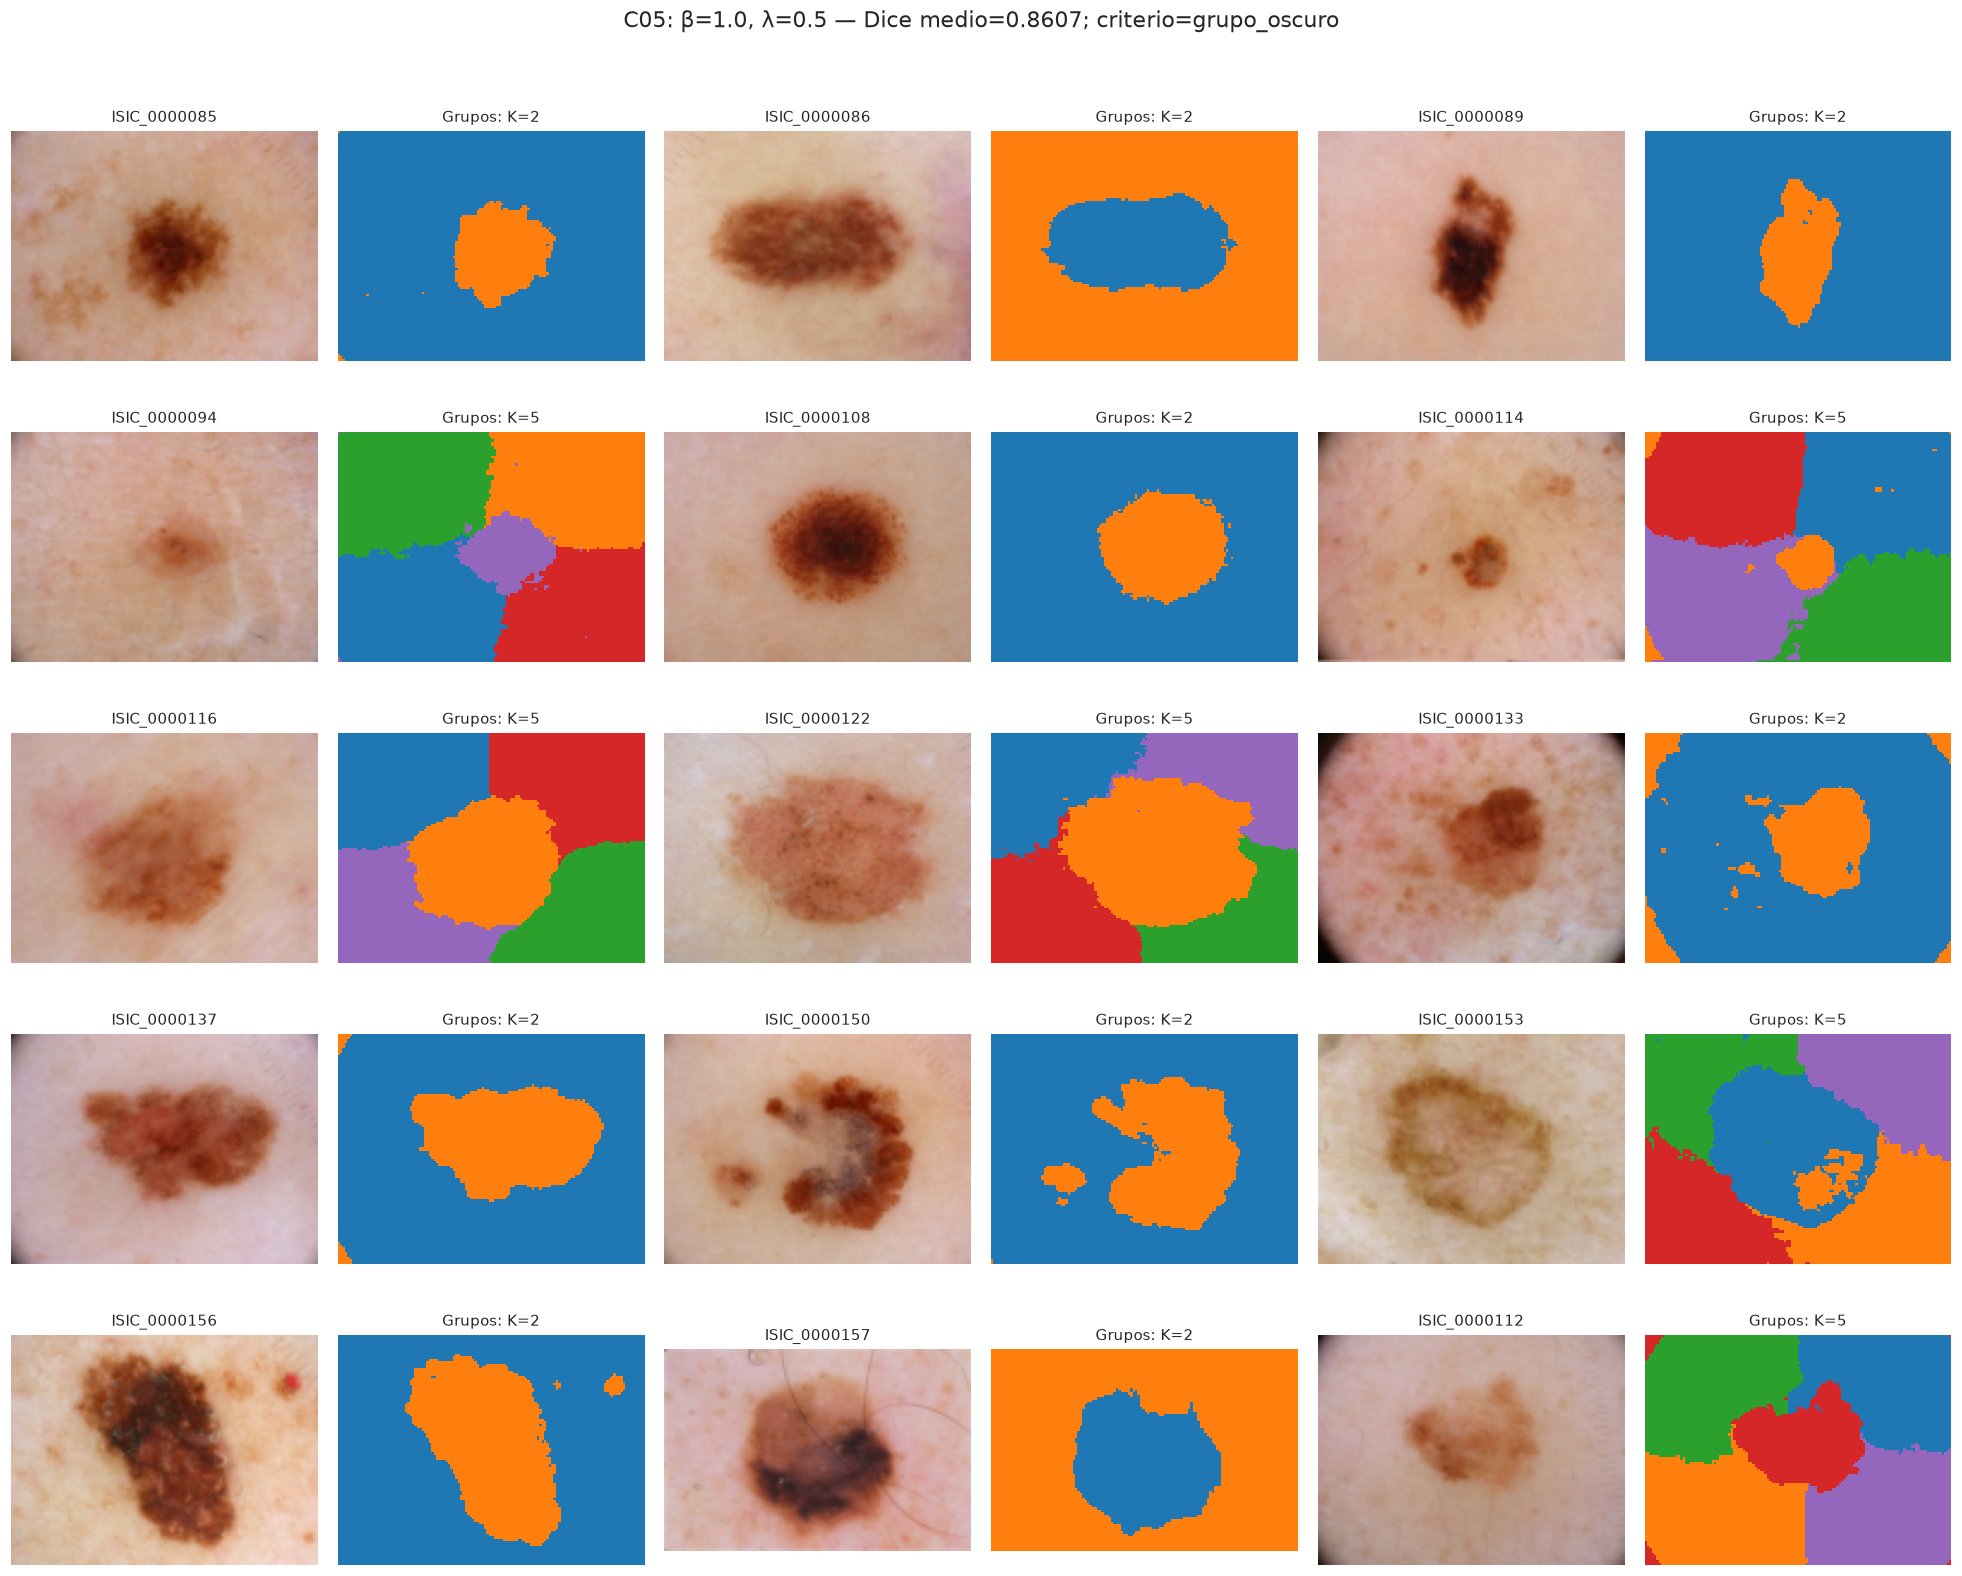

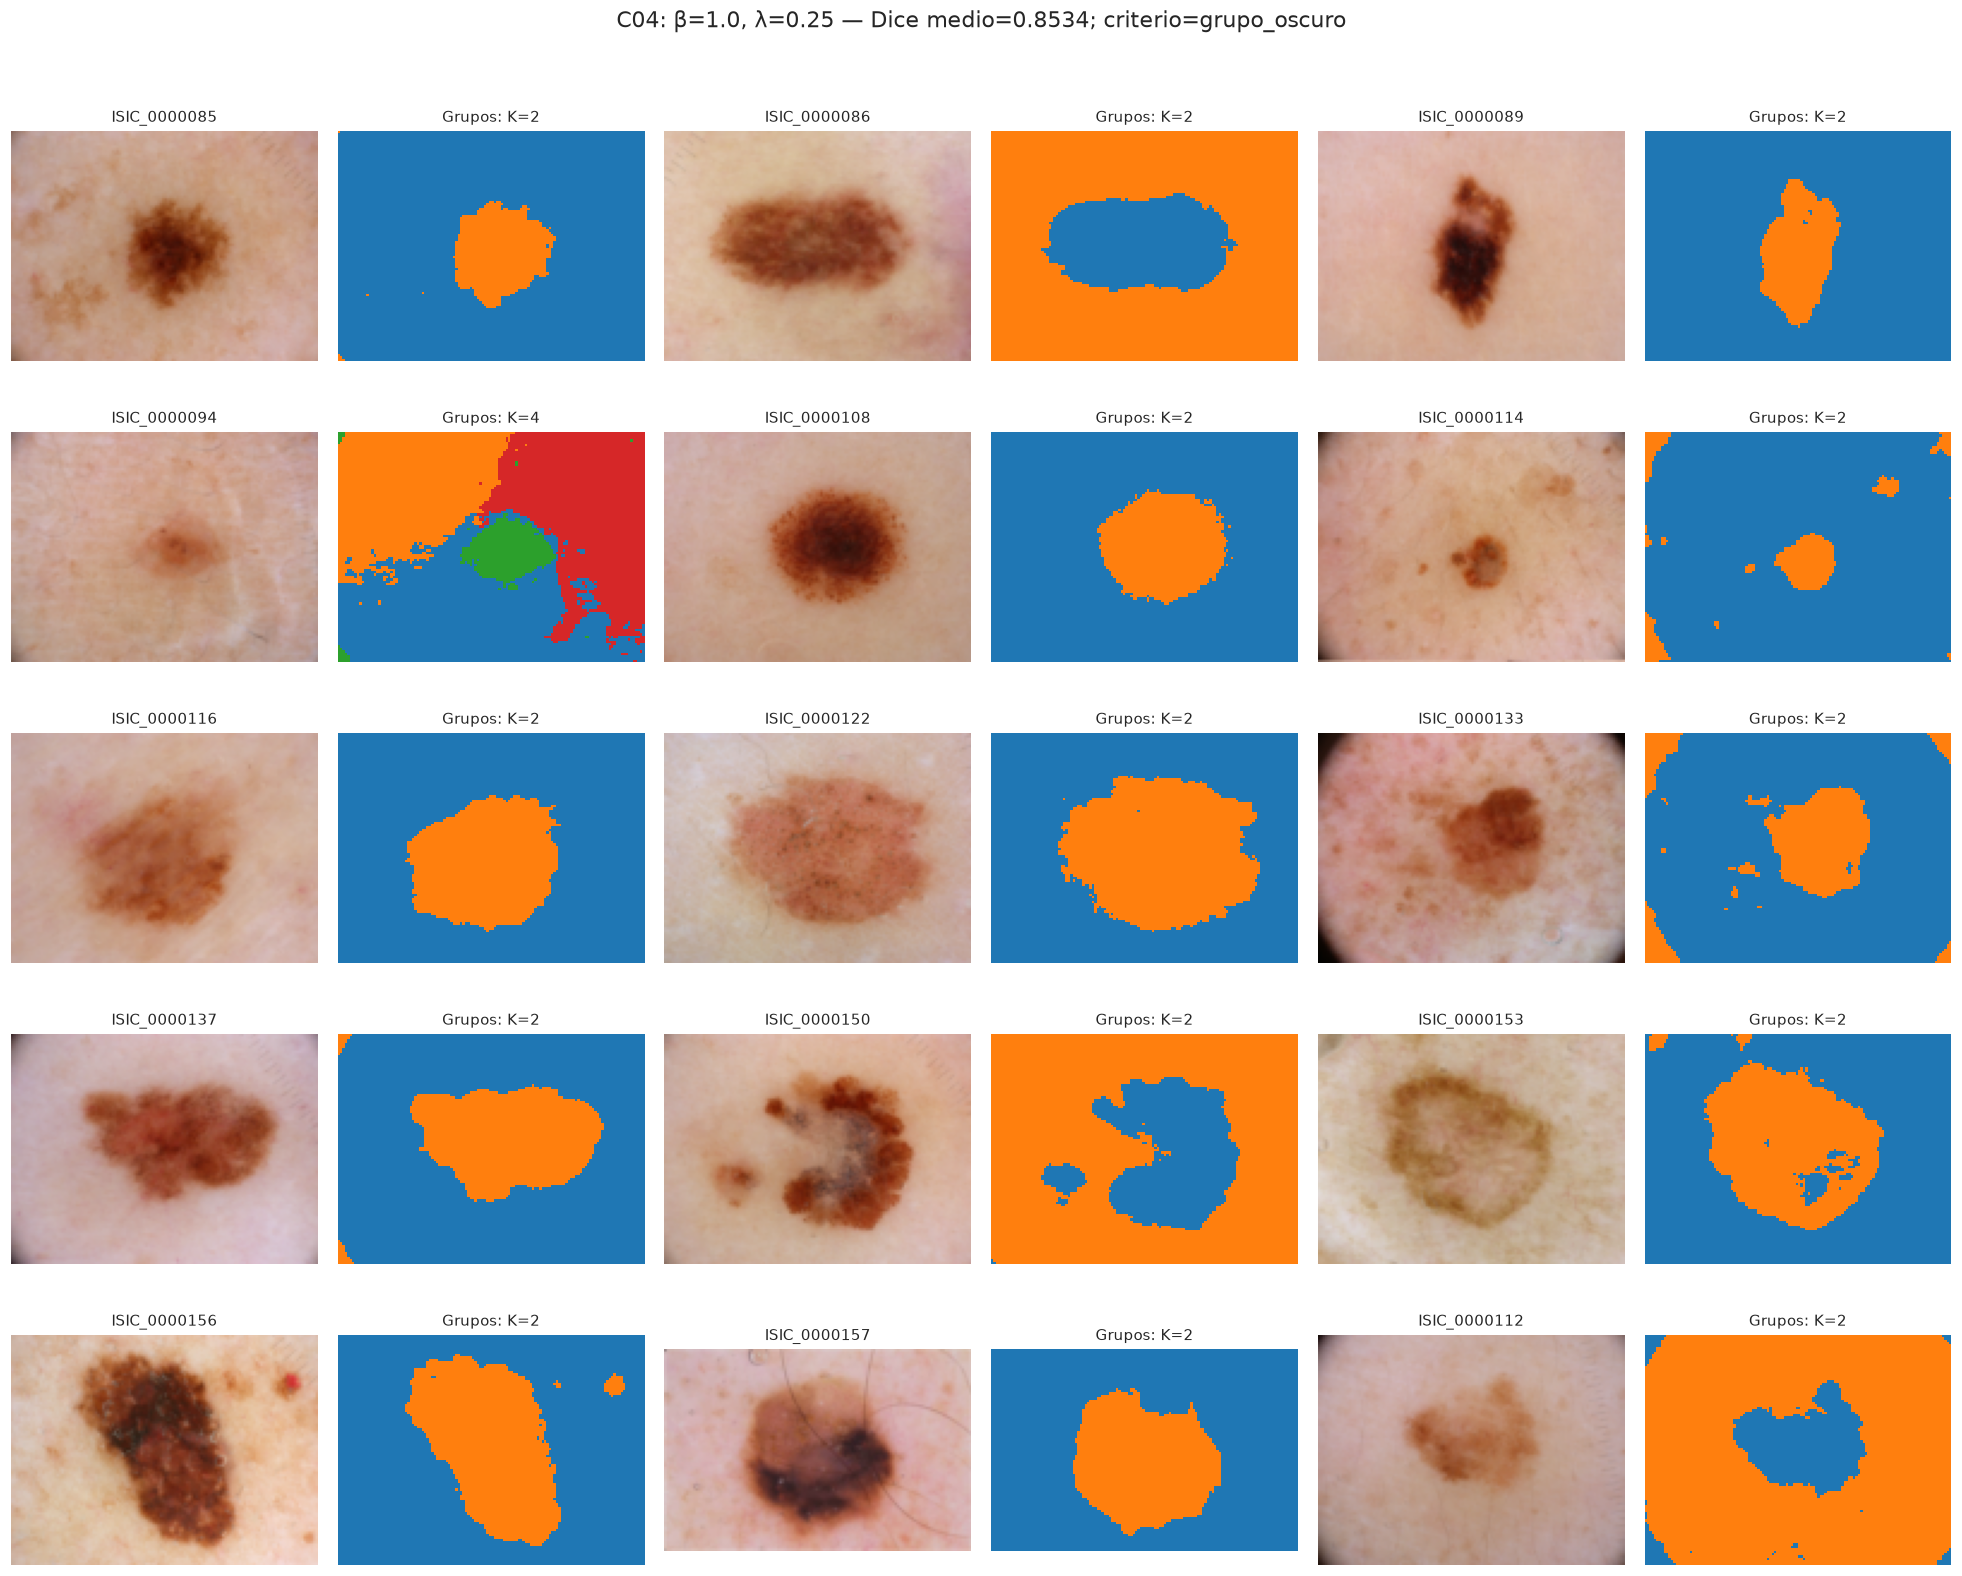

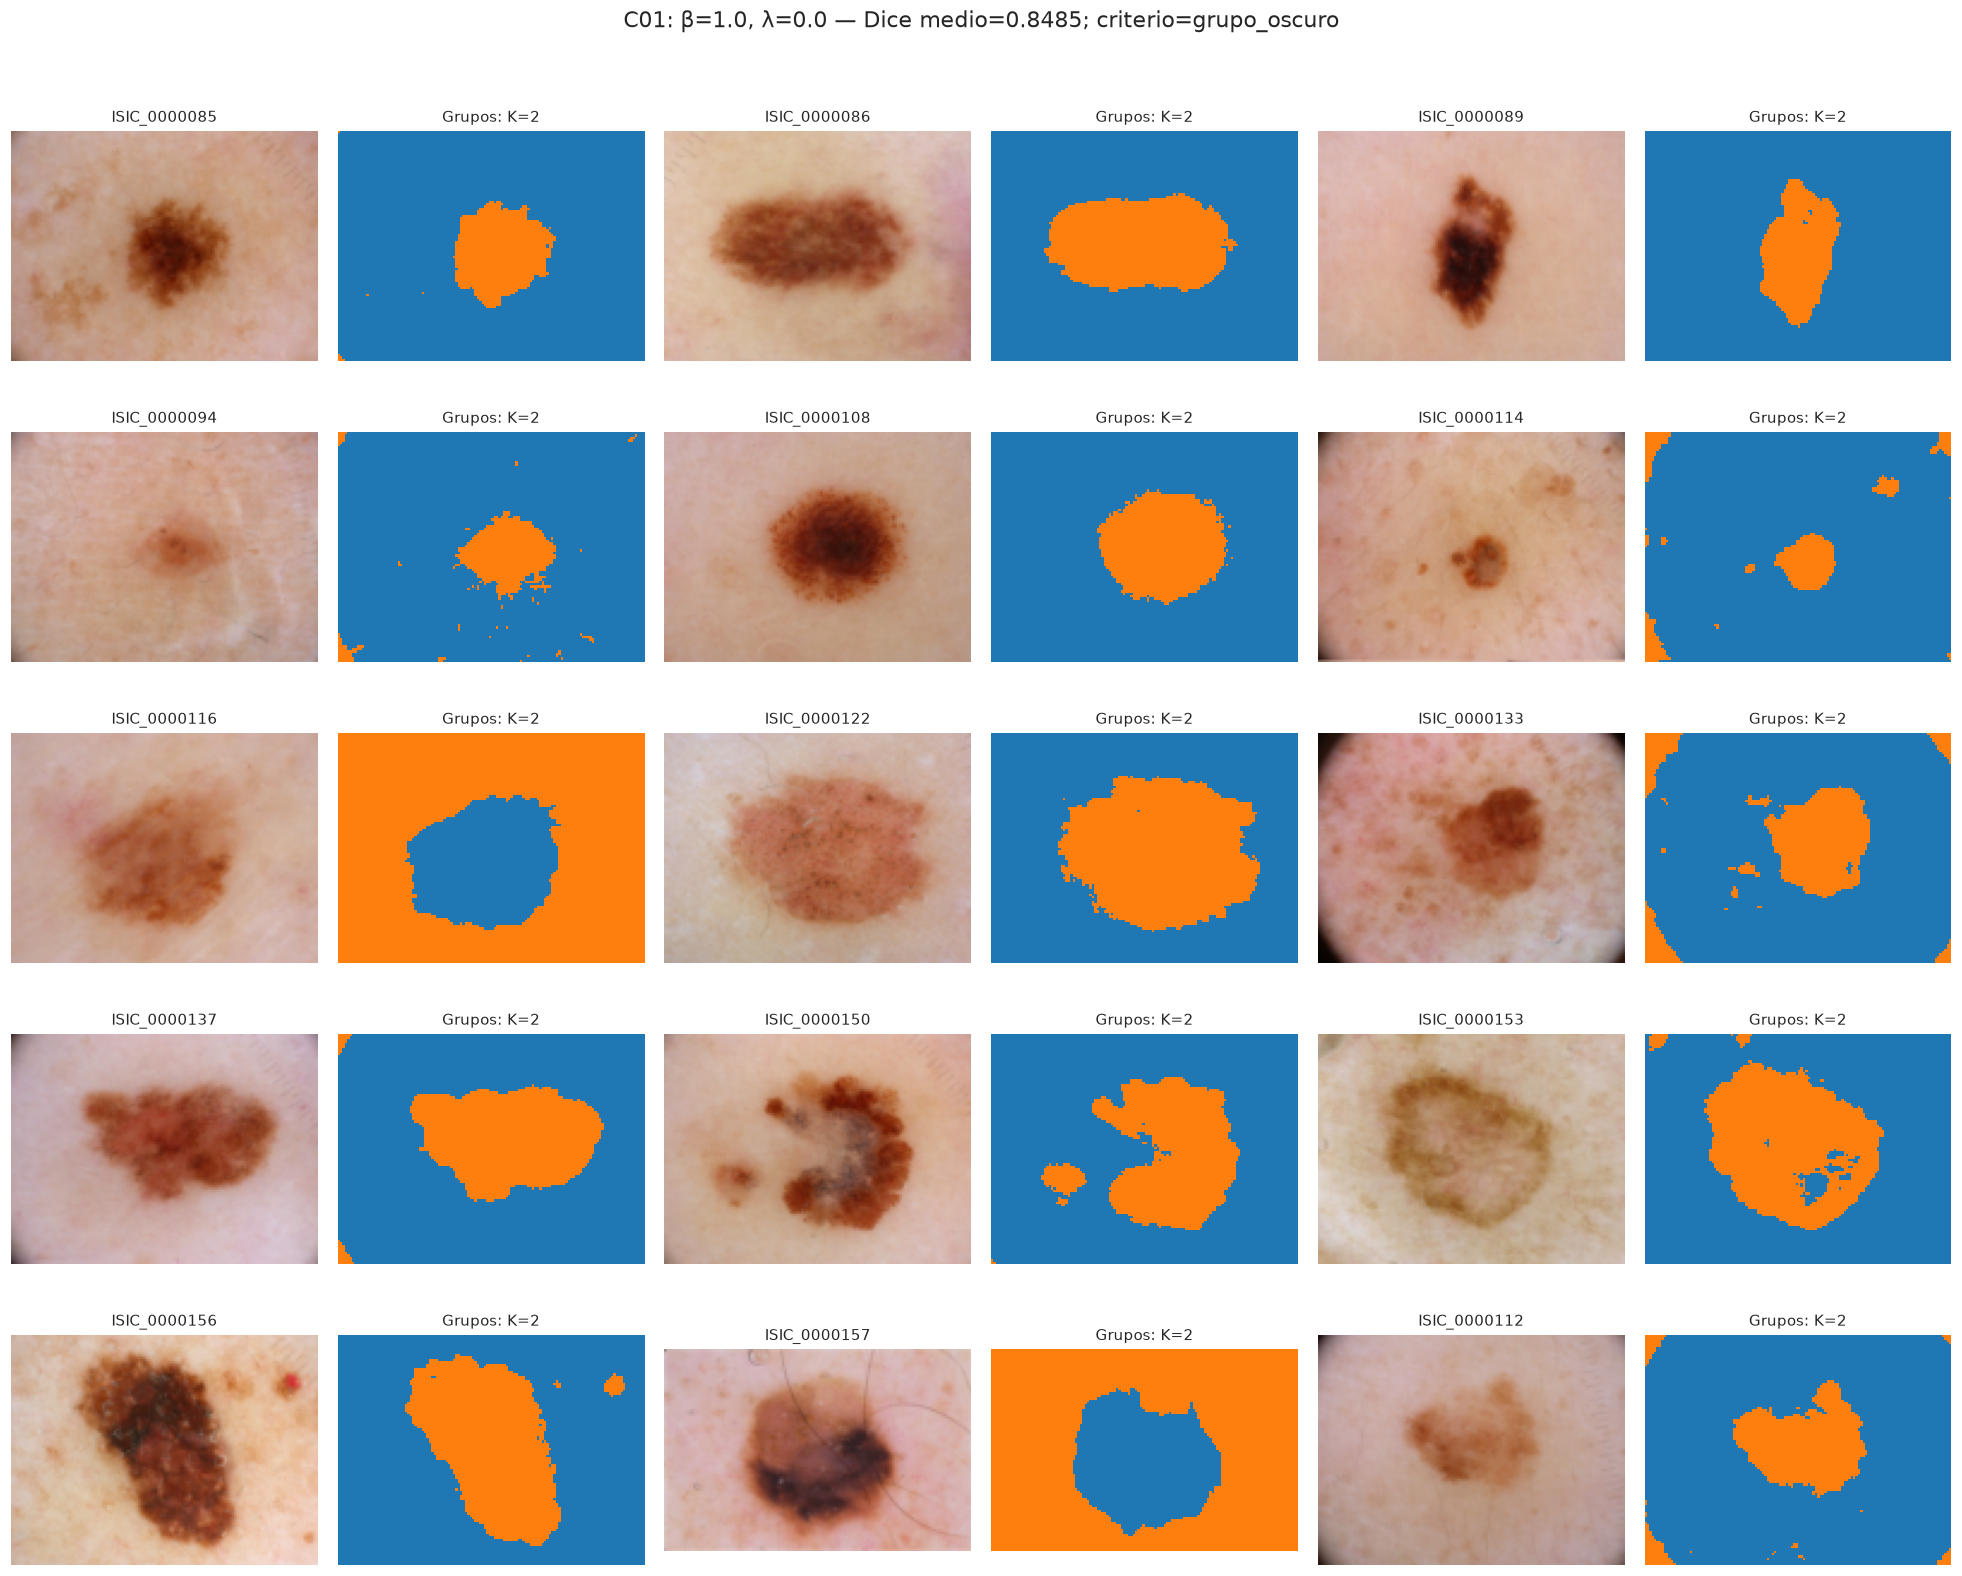

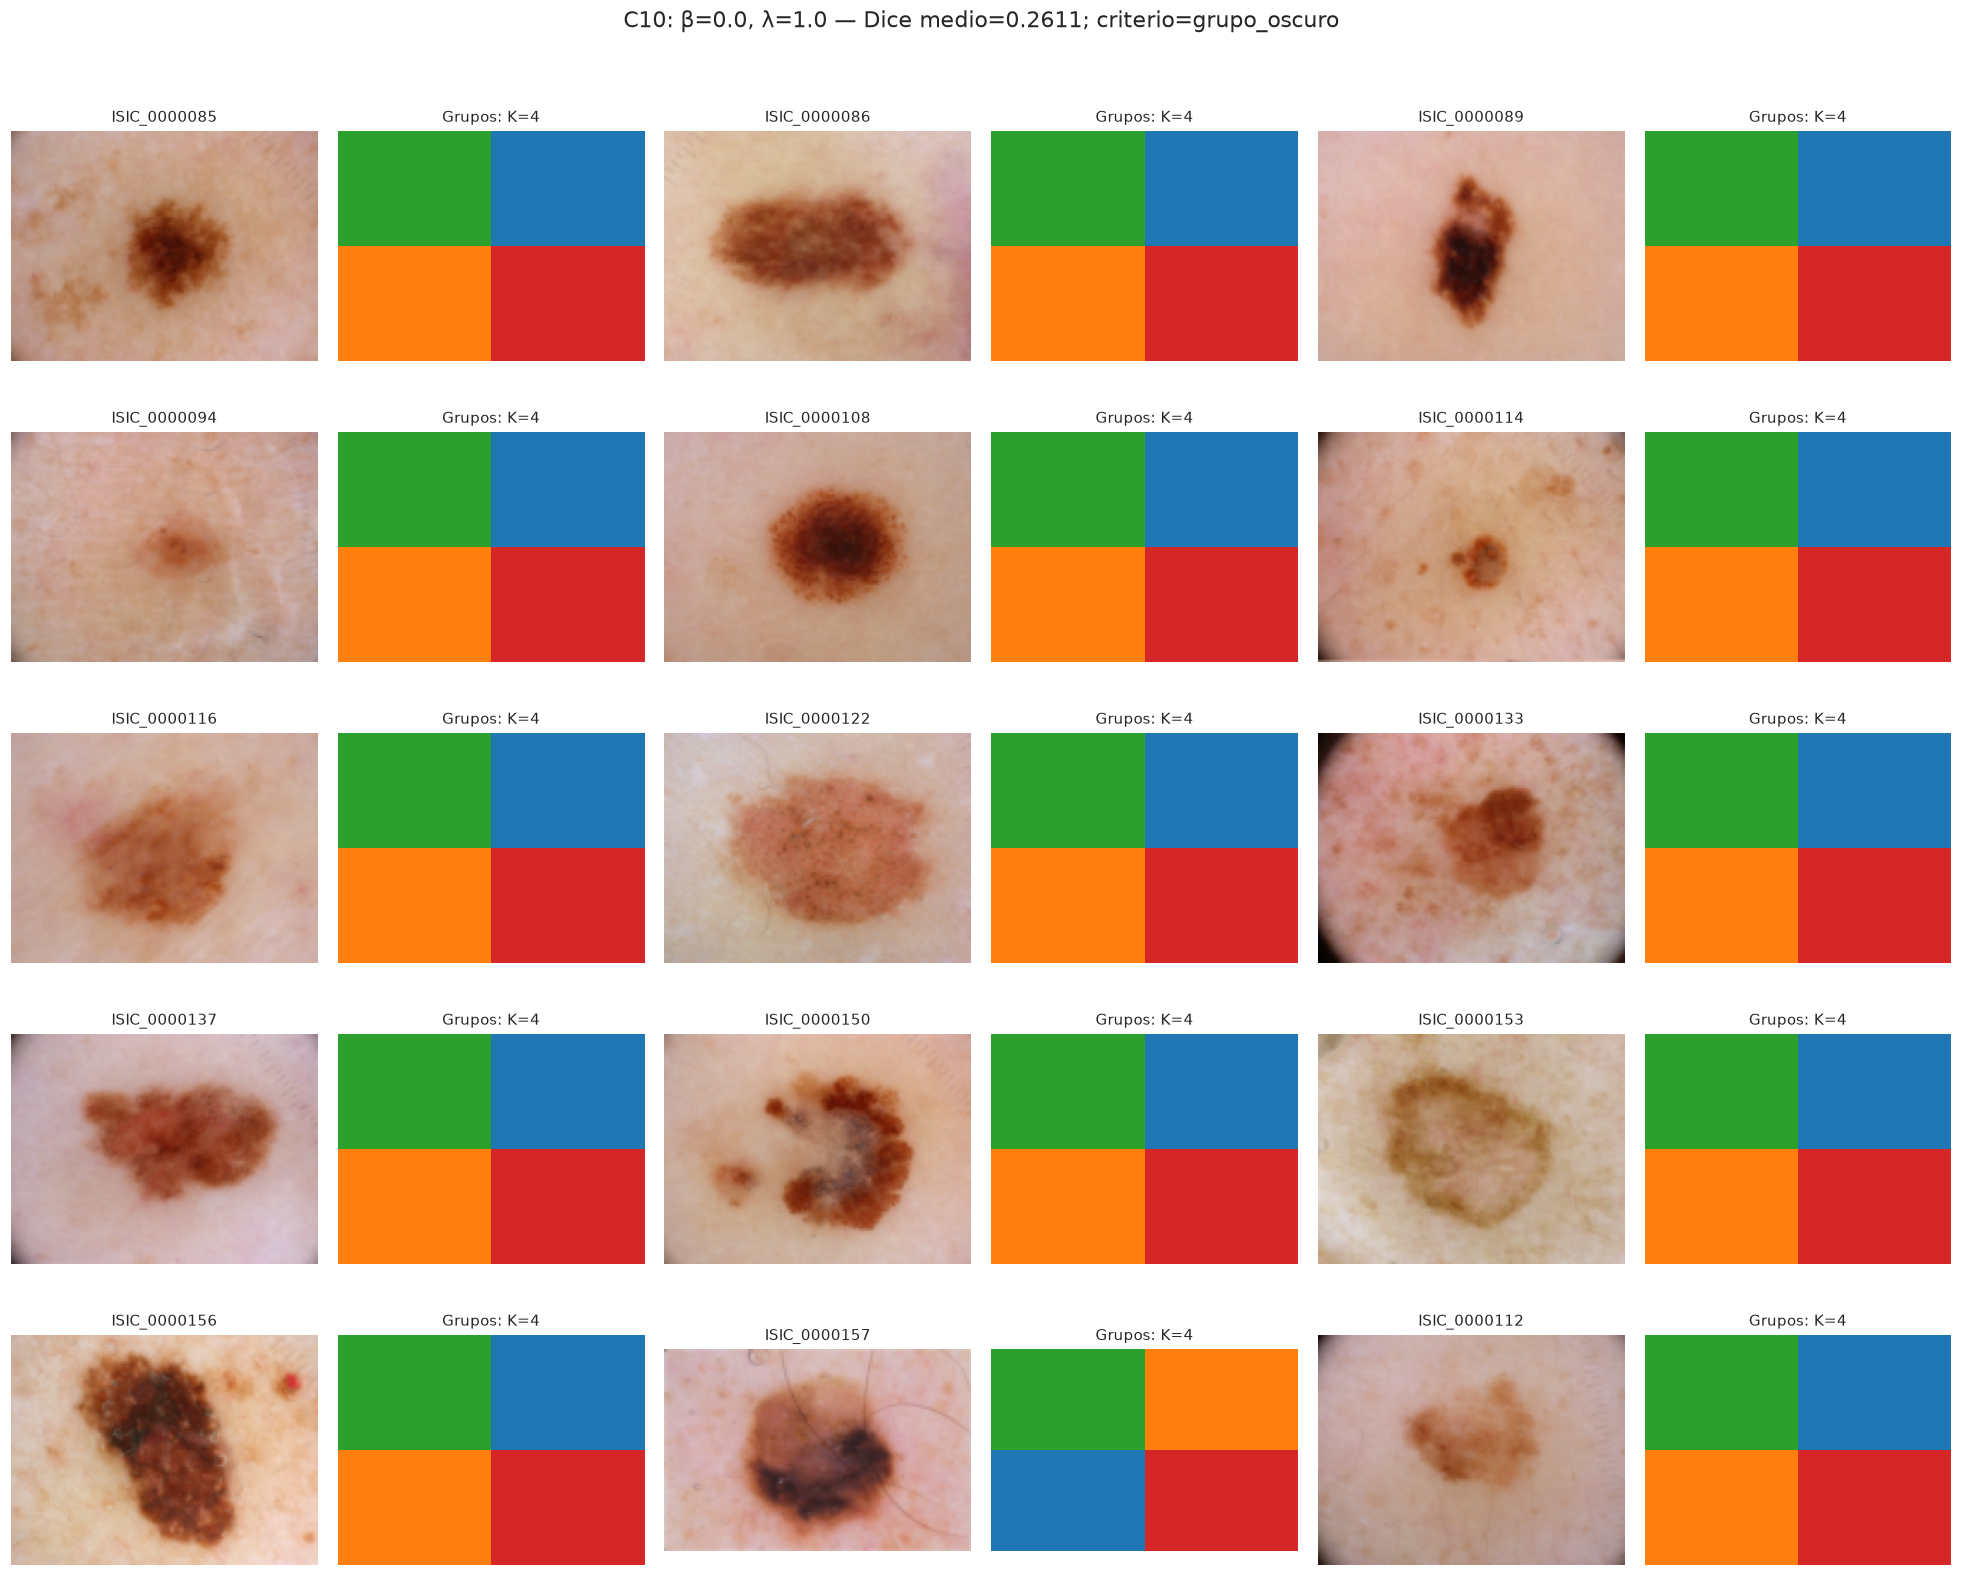

,imagen,K,silueta,Dice,V_measure,precision,recall,FP,FN
84,ISIC_0000133,2,0.4349,0.7396,0.4258,0.6827,0.8068,652,336
54,ISIC_0000114,5,0.3620,0.7439,0.1084,0.6468,0.8753,184,48
64,ISIC_0000116,5,0.4445,0.7448,0.2845,0.9996,0.5935,1,1804


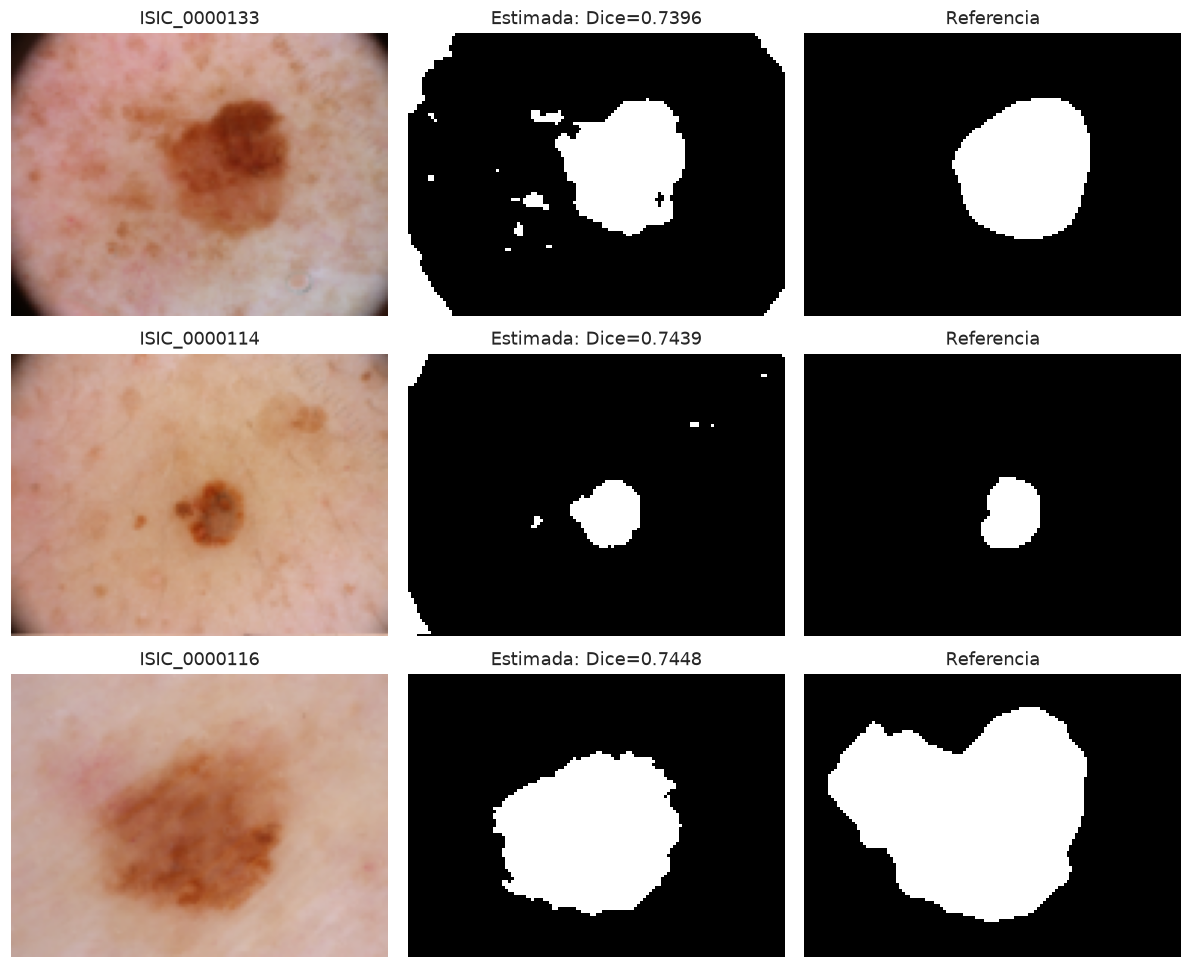

In [8]:
configuraciones_visuales = pd.concat([
    ranking_ajuste.head(2),
    ranking_ajuste[(ranking_ajuste["beta"] == 1) & (ranking_ajuste["lambda"] == 0)].head(1),
    ranking_ajuste[(ranking_ajuste["beta"] == 0) & (ranking_ajuste["lambda"] == 1)].head(1),
]).drop_duplicates(["configuracion", "criterio"])

for config in configuraciones_visuales.to_dict("records"):
    fig, ejes = plt.subplots(5, 6, figsize=(18, 15))
    for indice, identificador in enumerate(IDS_AJUSTE):
        fila, columna = indice // 3, 2 * (indice % 3)
        agrupacion = agrupaciones_ajuste[(identificador, config["configuracion"])]
        ejes[fila, columna].imshow(ajuste_preparado[identificador]["imagen"])
        ejes[fila, columna].set_title(identificador, fontsize=10)
        ejes[fila, columna + 1].imshow(agrupacion["grupos"], cmap="tab10", vmin=0, vmax=9,
                                      interpolation="nearest")
        ejes[fila, columna + 1].set_title(f"Grupos: K={agrupacion['K']}", fontsize=10)
    for eje in ejes.flat:
        eje.axis("off")
    fig.suptitle(f"{config['configuracion']}: β={config['beta']}, λ={config['lambda']} — "
                 f"Dice medio={config['Dice_promedio']:.4f}; criterio={config['criterio']}")
    plt.tight_layout(rect=(0, 0, 1, .97))
    plt.show()

primera_provisional = ranking_ajuste.iloc[0]
casos_revision = resultados_ajuste[
    (resultados_ajuste["configuracion"] == primera_provisional["configuracion"]) &
    (resultados_ajuste["criterio"] == primera_provisional["criterio"])
].sort_values(["Dice", "imagen"]).head(3)
display(casos_revision[["imagen", "K", "silueta", "Dice", "V_measure", "precision", "recall", "FP", "FN"]].round(4))
fig, ejes = plt.subplots(len(casos_revision), 3, figsize=(11, 9), squeeze=False)
for fila, caso in enumerate(casos_revision.to_dict("records")):
    identificador = caso["imagen"]
    ejes[fila, 0].imshow(ajuste_preparado[identificador]["imagen"])
    ejes[fila, 0].set_title(identificador)
    ejes[fila, 1].imshow(mascaras_ajuste[(identificador, caso["configuracion"], caso["criterio"])],
                        cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ejes[fila, 1].set_title(f"Estimada: Dice={caso['Dice']:.4f}")
    ejes[fila, 2].imshow(ajuste_preparado[identificador]["referencia"], cmap="gray", vmin=0, vmax=1,
                        interpolation="nearest")
    ejes[fila, 2].set_title("Referencia")
for eje in ejes.flat:
    eje.axis("off")
plt.tight_layout()
plt.show()


**Interpretación de ajuste:**

Entre las diez combinaciones evaluadas con `grupo_oscuro`, **C05 (β = 1, λ = 0,5)** ocupa provisionalmente el primer lugar: Dice promedio **0,8607**, desviación estándar **0,0771** y mínimo **0,7396**. Le sigue **C04 (β = 1, λ = 0,25)** con **0,8534**. La diferencia entre sus medias es **0,0073**; esta comparación descriptiva no demuestra una diferencia estadísticamente significativa ni garantiza el mismo orden en imágenes nuevas.

Solo color (C01) obtiene **0,8485**, mientras que solo posición (C10) alcanza **0,2611**. La ganancia promedio de C05 frente a solo color es **0,0123**: incluir posición de forma moderada ayuda en promedio en esta selección, pero no implica mejorar cada imagen. Con λ = 8 el Dice cae a **0,2620**, consistente con una agrupación dominada por la posición que no sigue adecuadamente las diferencias de color. En solo posición, la elección posterior del grupo oscuro sigue usando RGB, como se explicó en la sección 6.

V-measure no produce el mismo orden: solo color obtiene **0,6458**, frente a **0,5278** de C05. Esto ilustra que la correspondencia entre todos los grupos y la referencia no equivale a la superposición de la máscara binaria elegida. La silueta tampoco sustituye Dice para comparar configuraciones de segmentación.

En los tres peores casos de C05 se observan mecanismos distintos:

- **ISIC_0000133:** Dice **0,7396**, precisión **0,6827** y recall **0,8068**. La estimación incluye zonas oscuras de las esquinas y otros píxeles fuera de la lesión: **652 falsos positivos** y **336 falsos negativos** a la resolución de trabajo. El grupo oscuro reúne tanto lesión como elementos del borde.
- **ISIC_0000114:** Dice **0,7439**, precisión **0,6468** y recall **0,8753**. La lesión pequeña se recupera en gran parte, pero aparecen regiones periféricas y puntos adicionales: **184 falsos positivos** y **48 falsos negativos**.
- **ISIC_0000116:** Dice **0,7448**, precisión **0,9996** y recall **0,5935**. La máscara selecciona una parte oscura interior, pero excluye zonas claras de la lesión: **1 falso positivo** y **1.804 falsos negativos**. Escoger un único grupo puede subsegmentar una lesión de varios tonos.

Las visualizaciones completas permiten revisar ambos primeros lugares y los extremos sin limitarse a ejemplos favorables. El análisis respalda considerar C05 como candidata, pero **la elección final queda pendiente de la verificación obligatoria de IAG**. Los resultados son de ajuste, sobre máscaras reducidas; no constituyen una estimación independiente del desempeño futuro y no se han consultado imágenes de prueba.

## 8.2 Configuración final — pendiente de la sección 7
Se dispone del ranking de ajuste, pero **no se adopta una configuración final** todavía. Primero debe completarse la consulta y verificación de IAG de la sección 7, tal como exige el enunciado. Si esa actividad lleva a proponer cambios, deben evaluarse únicamente en ajuste y documentarse antes de tomar la decisión final.

Después se registrarán β, λ, criterio y justificación basada en Dice promedio, junto con resolución, muestreo, semilla, inicializaciones y regla de selección de K. Solo entonces se podrá pasar a prueba sin realizar nuevas modificaciones.


In [9]:
# No confundir el primer lugar del ranking provisional con una decisión final.
configuracion_final = None
print("Configuración final pendiente: completar y analizar primero la sección 7.")


Configuración final pendiente: completar y analizar primero la sección 7.


# 9. Evaluación en prueba
**Actividad 5 · 10% evaluación y presentación.**

Aplicar la configuración seleccionada, sin modificaciones, a las cinco imágenes reservadas. Presentar una tabla por imagen con K seleccionado, silueta, Dice, V-measure, precisión y recall; lesión es la clase positiva. Incluir original, máscara estimada y referencia. Comparar el Dice promedio de ajuste y prueba.

**Interpretación:** completar los aciertos, errores y comparación entre conjuntos sin modificar el método a partir de los resultados de prueba.

# 10. Análisis de resultados
**30%.** Responder con imágenes, tablas, identificadores y valores obtenidos en el notebook.

## 10.1 Efecto de la posición y relación entre métricas (10%)
1. ¿Qué efecto tuvo incluir la posición de los píxeles? ¿En qué imágenes mejoró o perjudicó la segmentación y por qué?
2. ¿Qué relación encontraron entre K, silueta y Dice? ¿Por qué no necesariamente conducen a las mismas decisiones?

**Respuestas:** por completar.

## 10.2 Comparación ajuste/prueba (5%)
3. ¿Cómo se comparan los resultados de ajuste y prueba? ¿Por qué es importante no modificar el método después de consultar las máscaras de prueba?

**Respuesta:** por completar.

## 10.3 Limitaciones (5%)
4. Identificar dos limitaciones del modelo y explicar sus causas con evidencia de las imágenes y de la representación RGB + posición.

**Respuesta:** por completar.

## 10.4 Riesgos, sesgos y generalización (10%)
5. ¿Qué consecuencias podrían tener los falsos positivos y falsos negativos para DermAlpes? ¿Qué sesgos y problemas de generalización deben considerarse con otras poblaciones o condiciones de adquisición?

**Respuesta:** por completar.

# 11. Conclusiones

**Por completar:** sintetizar la configuración seleccionada, resultados de prueba, principales limitaciones y recomendaciones para DermAlpes. Sustentar cada conclusión en los resultados propios.

# 12. Guion del video
**Actividad 6 · 5%. Máximo tres minutos.**

**Por completar:** guion para DermAlpes y público no especializado que explique el problema, cómo se obtiene la máscara a partir de grupos, resultados de prueba, casos de fallo y precauciones. Incluir enlace o nombre del archivo y duración final.

# 13. Uso de herramientas de IA generativa
**10%, incluyendo la verificación de la sección 7.**

## 13.1 Declaración de uso
Se utilizó ChatGPT / Codex (OpenAI) como apoyo para estructurar esta plantilla y revisar su correspondencia con el enunciado y la rúbrica. Se generó una versión inicial con código, posteriormente retirada para conservar únicamente la plantilla.

**Por completar:** registrar otros usos reales y herramientas utilizadas.

## 13.2 Prompts e historial
**Por completar:** documentar los prompts principales e incluir el historial de la consulta obligatoria de verificación.

## 13.3 Análisis crítico
**Por completar:** partes útiles, errores o limitaciones identificados, decisiones modificadas y conceptos del curso utilizados para evaluar las respuestas. Incorporar los aciertos y fallos de la recomendación verificada.

## 13.4 Aportes propios
**Por completar:** explicar qué desarrollaron, modificaron o decidieron los estudiantes y qué aprendieron del proceso.

# 14. Referencias y revisión de entregables

- Enunciado: `Laboratorio 4_Segmentación de imágenes.md`.
- Rúbrica PDF del Laboratorio 4, 14 páginas.
- [ISIC 2016 — tarea 1](https://challenge.isic-archive.com/landing/2016/37/).
- **Por completar:** fecha de consulta y fuentes técnicas utilizadas.

## Lista de revisión

- [ ] Integrantes confirmados y registrados en Bloque Neón.
- [ ] Pipeline y máscaras correctamente preparados (10%).
- [ ] Diez pesos y K=2,…,8 por silueta reproducible (10%).
- [ ] Criterio automático implementado y justificado (15%).
- [ ] Ajuste con 15 imágenes y selección por Dice promedio (10%).
- [ ] Evaluación de cinco imágenes con métricas y visualizaciones (10%).
- [ ] Cinco preguntas respondidas con evidencia (30%).
- [ ] Video de máximo tres minutos (5%).
- [ ] Declaración de IAG e historial de verificación con análisis crítico (10%).
- [ ] Notebook ejecutado con salidas visibles, exportación HTML y video.
- [ ] Sin espacios por completar pendientes al entregar.

# 15. Bonos
Opcionales; solo se califican con las actividades obligatorias completas. Hasta 0,25 puntos por bono, máximo 0,5 sin superar 5,0.

## 15.1 Visualización del espacio de representación
Aplicar PCA o t-SNE a una muestra de píxeles de una imagen. Presentar la proyección coloreada por clúster y por referencia. Interpretar coincidencias, diferencias y limitaciones de la proyección.

**Desarrollo e interpretación:** por completar si se realiza.

## 15.2 Comparación con mean shift
Investigar y explicar mean shift y el ancho de banda. Aplicarlo a una imagen de ajuste con resolución y muestra viables. Construir máscara y comparar con K-medias mediante Dice, visualizaciones y tiempo. Explicar por qué no requiere fijar K.

**Desarrollo, fuentes e interpretación:** por completar si se realiza.